In [1]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2018.scaled')
data={
    '2018':{
        'sre': 'EGamma',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'EGamma',
        'ttbare': 'EGamma',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [9]:
data_hists['mT_corrected'].integrate("systematic").integrate('region','wjete')[data['2018']['sre']].values()

{('EGamma',): array([4.10000e+01, 7.29170e+04, 2.54593e+05, 1.50776e+05, 5.21860e+04,
        1.80040e+04, 8.07700e+03, 4.43600e+03, 2.56500e+03, 1.51600e+03,
        1.01500e+03, 6.57000e+02, 4.72000e+02, 2.96000e+02, 2.27000e+02,
        1.85000e+02, 1.38000e+02, 1.04000e+02, 8.00000e+01, 6.30000e+01])}

In [27]:
signal_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').values()

{('Mphi-1995_Mchi-1000',): array([ 0.        ,  2.7360316 ,  8.53748797, 11.62586361, 20.47553624,
        32.53496459, 29.5703266 , 27.10648293, 28.51577185, 29.20810547,
        22.14658942, 19.45060767, 22.12069123, 11.03362775, 11.03109705,
         9.16376912, 11.25124028, 10.18903209,  8.87995588,  7.74677261]),
 ('Mphi-2000_Mchi-1500',): array([ 0.        ,  2.32670535,  9.8108063 , 10.66806809, 13.81708423,
        26.54449812, 31.07991232, 33.03256633, 29.6596713 , 23.73476889,
        22.36066218, 20.58221591, 22.84925893, 17.41498778, 15.20838093,
        15.27252487, 14.6278629 , 10.09817935, 10.04468701,  9.0194729 ]),
 ('Mphi-2000_Mchi-500',): array([ 0.        ,  1.48523586,  9.48112596, 12.39758473, 17.43666938,
        32.47149193, 33.32417286, 30.62876345, 32.50235443, 28.59554668,
        22.41893501, 21.58701829, 16.90864599, 11.78511119, 11.70953452,
        13.78053049, 10.08290121,  5.54496875,  6.68022098,  7.0340633 ])}

In [20]:
data_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').values()[('EGamma',)]/bkg_hists['mT_corrected'].integrate('region','wjete').integrate('systematic', 'nominal').sum('process').values()[()]

array([       nan, 0.70461337, 0.71572356, 0.80849166, 0.87945742,
       0.83300594, 0.69860533, 0.65240369, 0.64896686, 0.49359069,
       0.54378088, 0.46566065, 0.55814353, 0.42062043, 0.57433805,
       0.72341815, 0.5434726 , 0.40978389, 0.3661763 , 0.55427171])

In [4]:
signal_hists

{'template': <Hist (process,region,systematic,mT_corrected) instance at 0x7f7348cbb908>,
 'ele_phi': <Hist (process,region,systematic,ele_phi) instance at 0x7f7348c17a20>,
 'sumw': <Hist (process,sumw) instance at 0x7f7348c1db38>,
 'j1pt': <Hist (process,region,systematic,j1pt) instance at 0x7f7348c1df98>,
 'eT_miss_corrected_phi': <Hist (process,region,systematic,eT_miss_corrected_phi) instance at 0x7f7348c260f0>,
 'metphi': <Hist (process,region,systematic,metphi) instance at 0x7f7348c2e208>,
 'ndflvM': <Hist (process,region,systematic,ndflvM) instance at 0x7f7348c34320>,
 'dr_mu_lj': <Hist (process,region,systematic,dr_mu_lj) instance at 0x7f7348c3a438>,
 'ele_pT': <Hist (process,region,systematic,ele_pT) instance at 0x7f7348c3f550>,
 'mu_eta': <Hist (process,region,systematic,mu_eta) instance at 0x7f7348c43668>,
 'j1phi': <Hist (process,region,systematic,j1phi) instance at 0x7f7348c4b780>,
 'leading_mu_pT': <Hist (process,region,systematic,leading_mu_pT) instance at 0x7f7348bd3898>

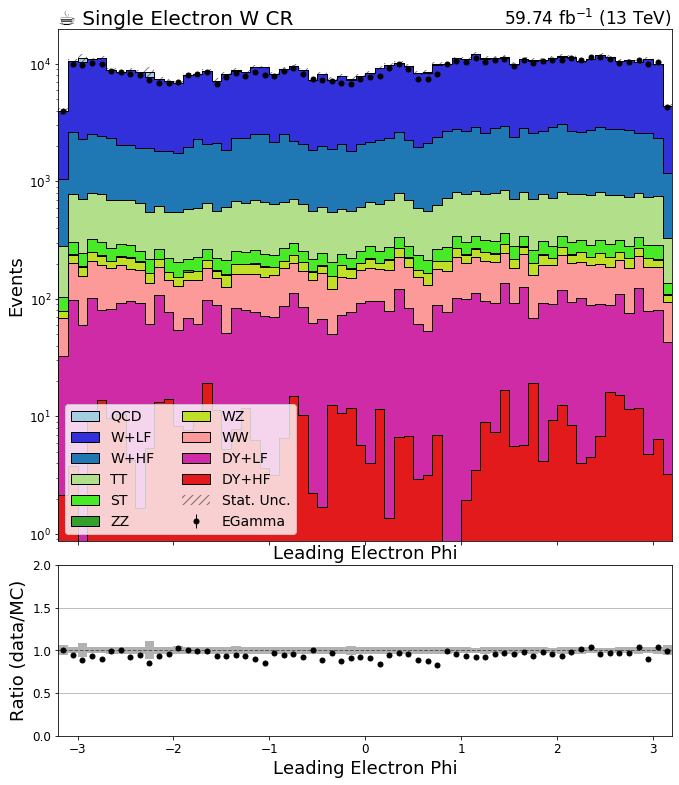

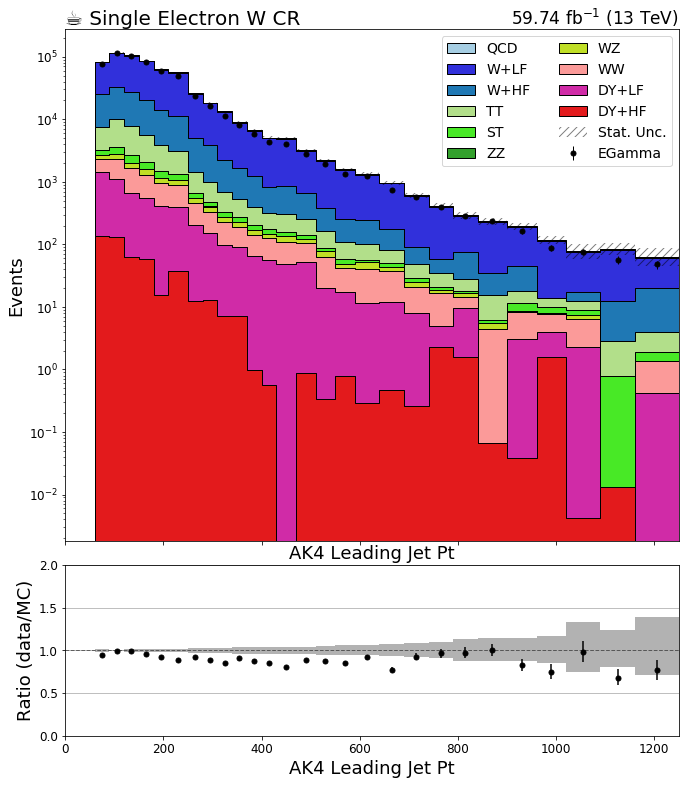

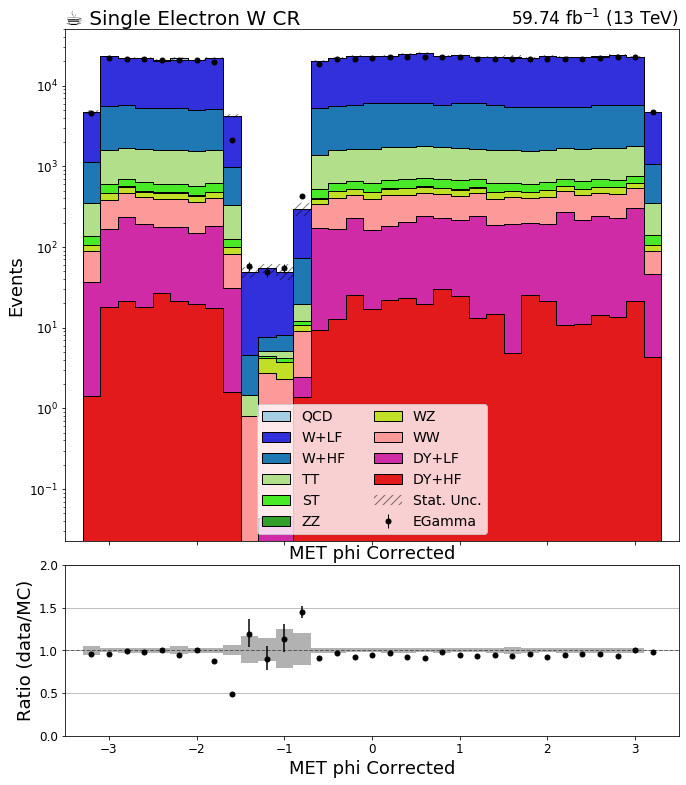

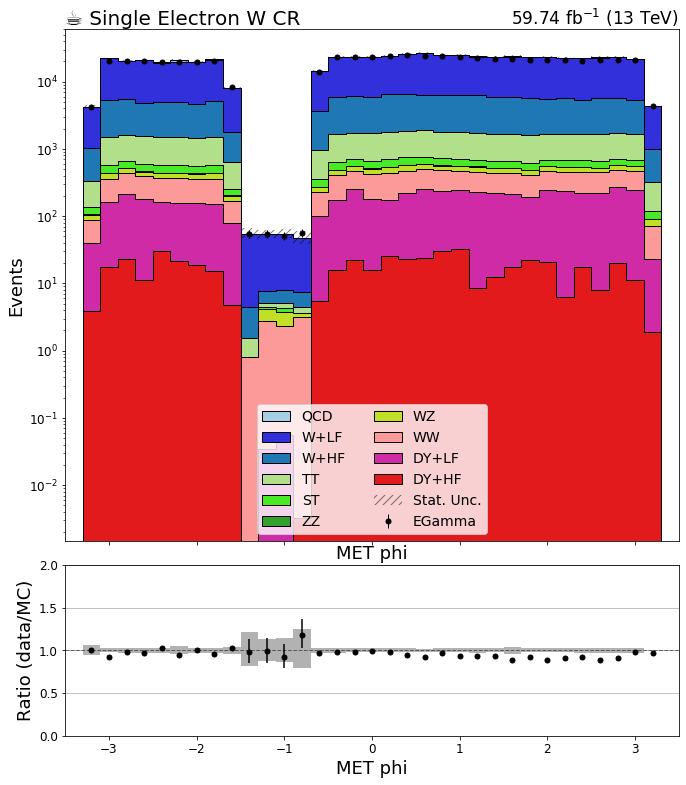

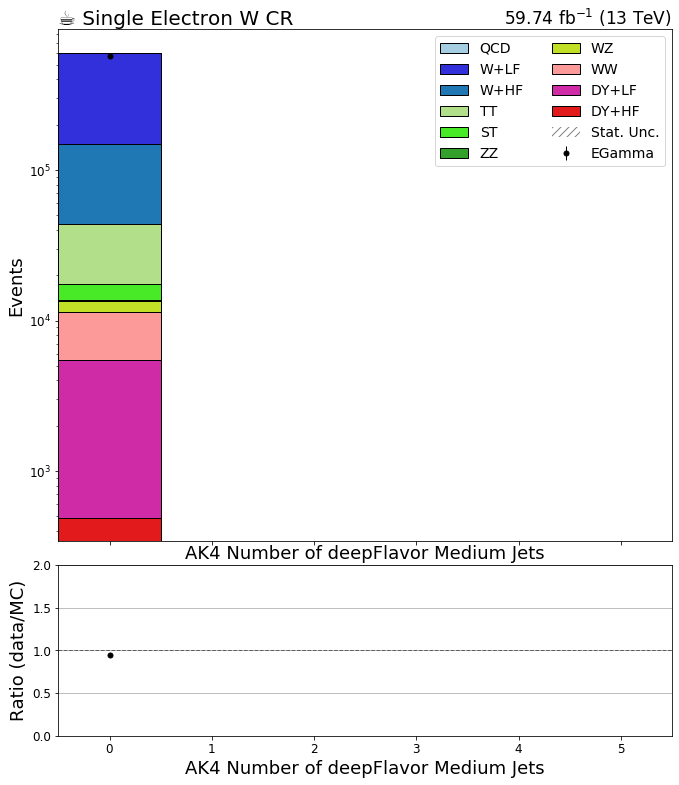

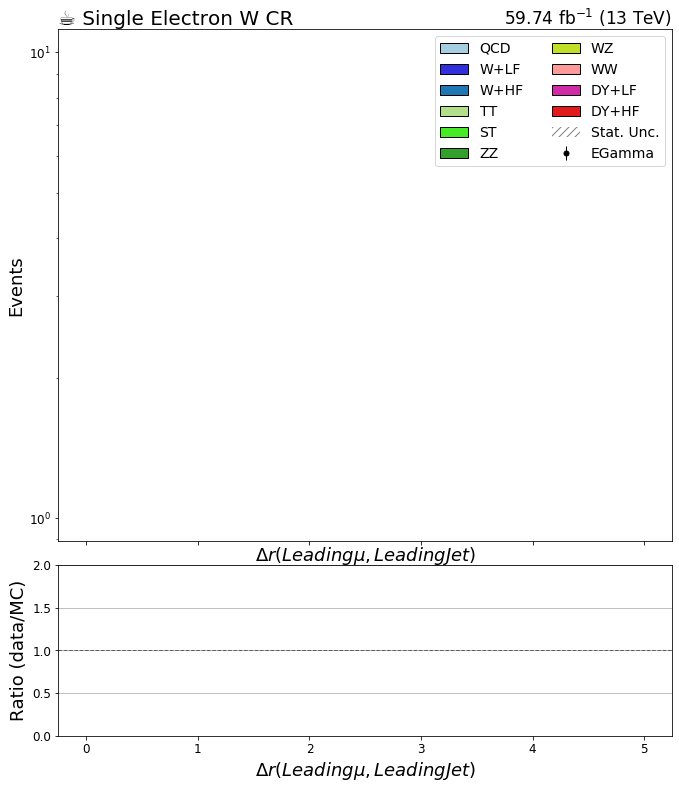

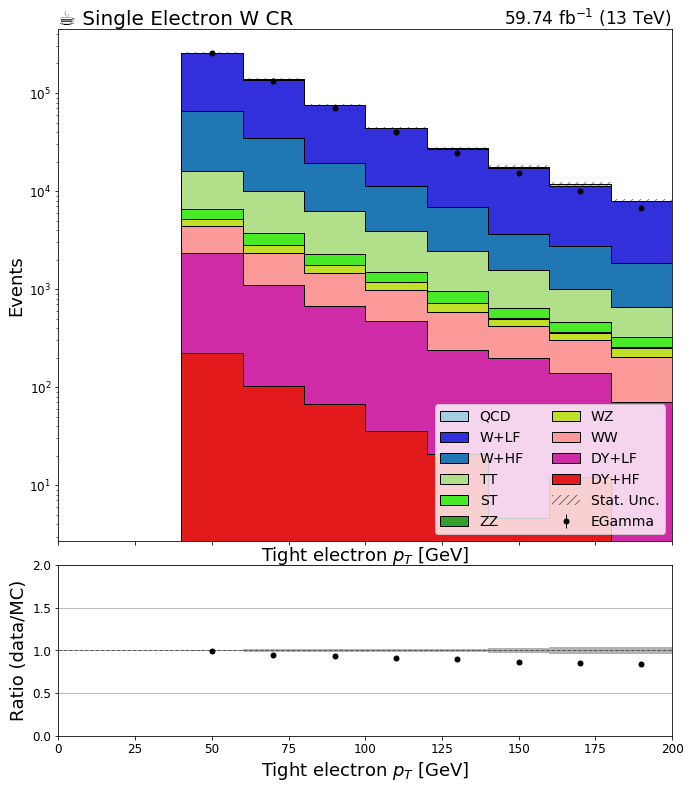

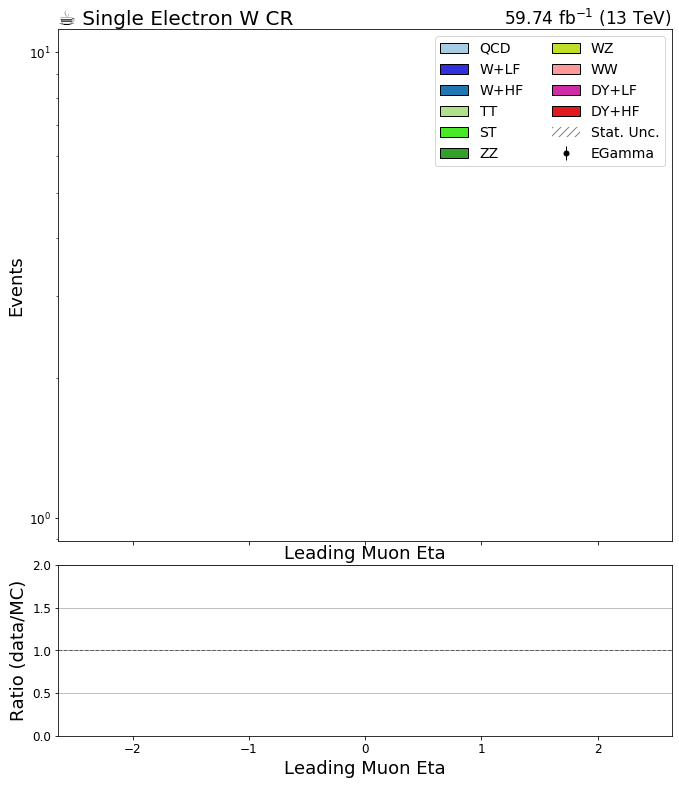

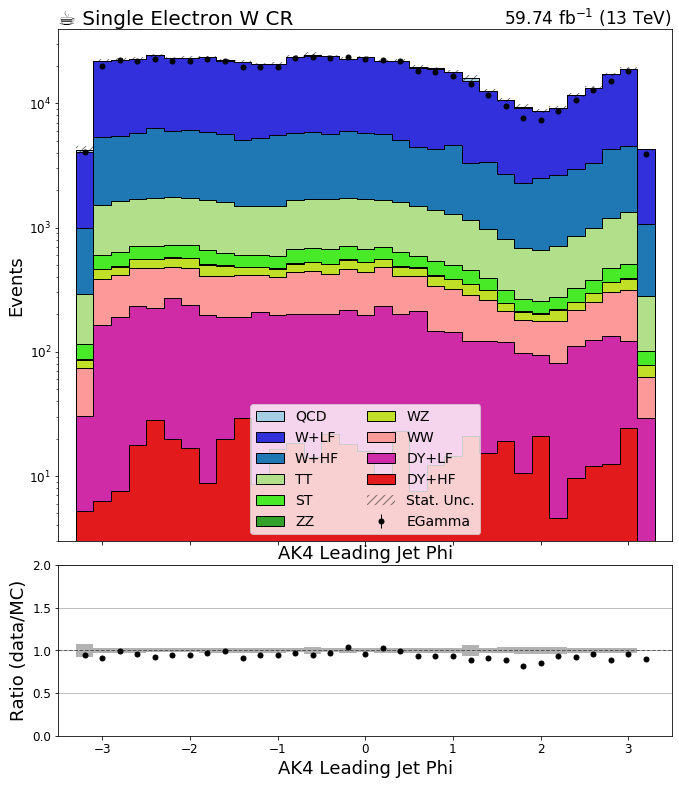

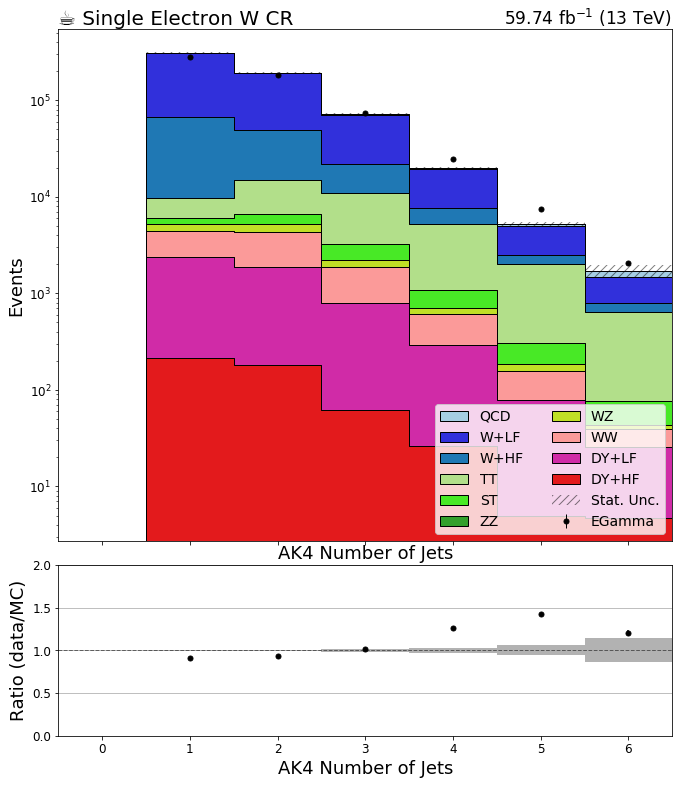

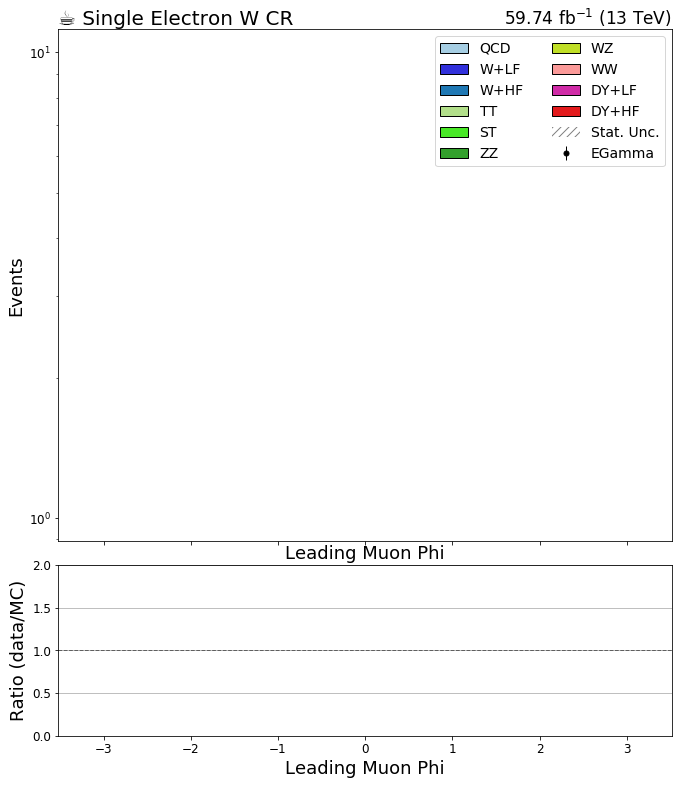

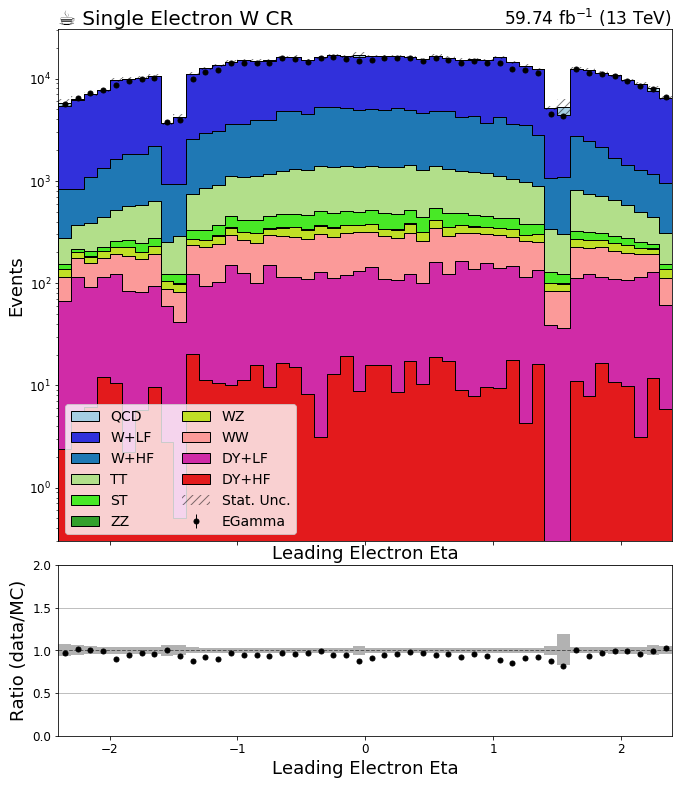

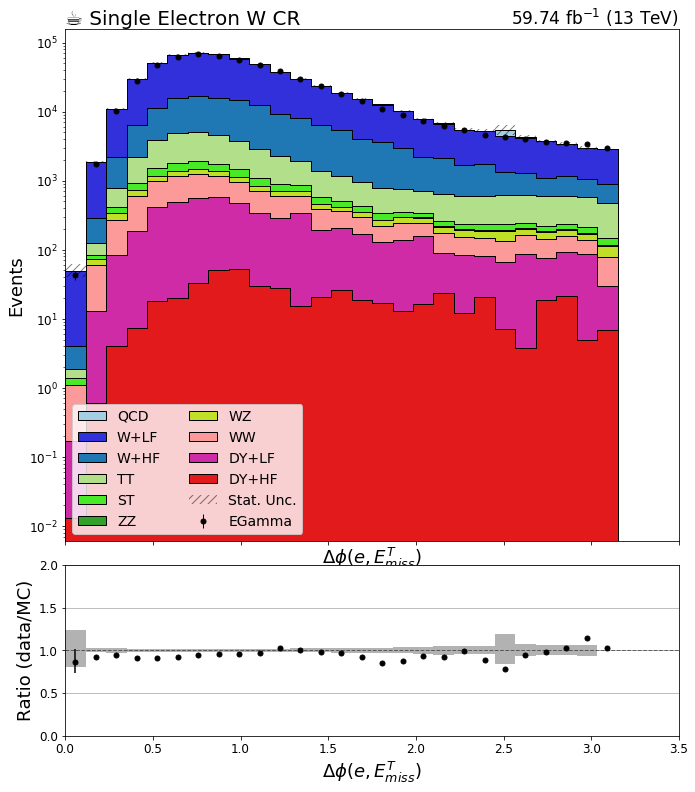

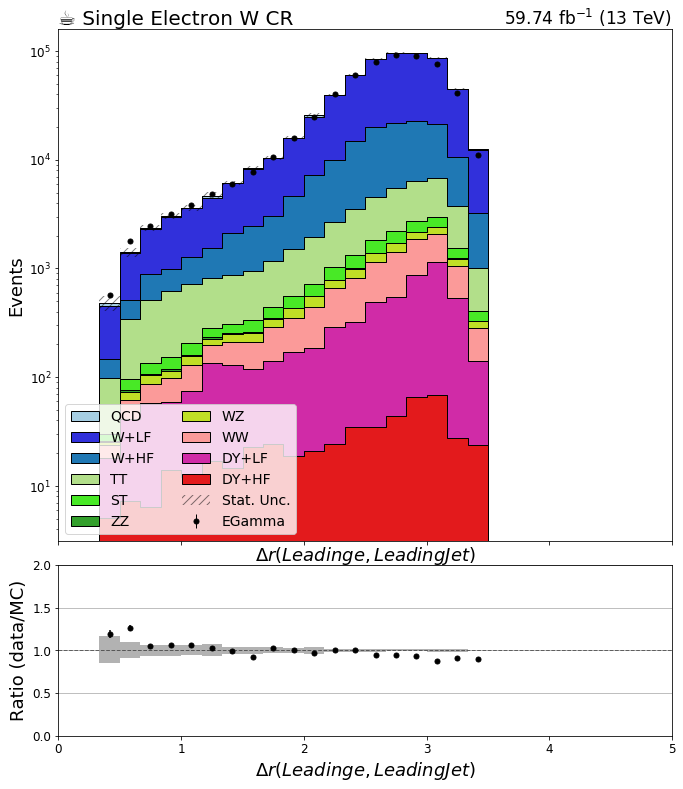

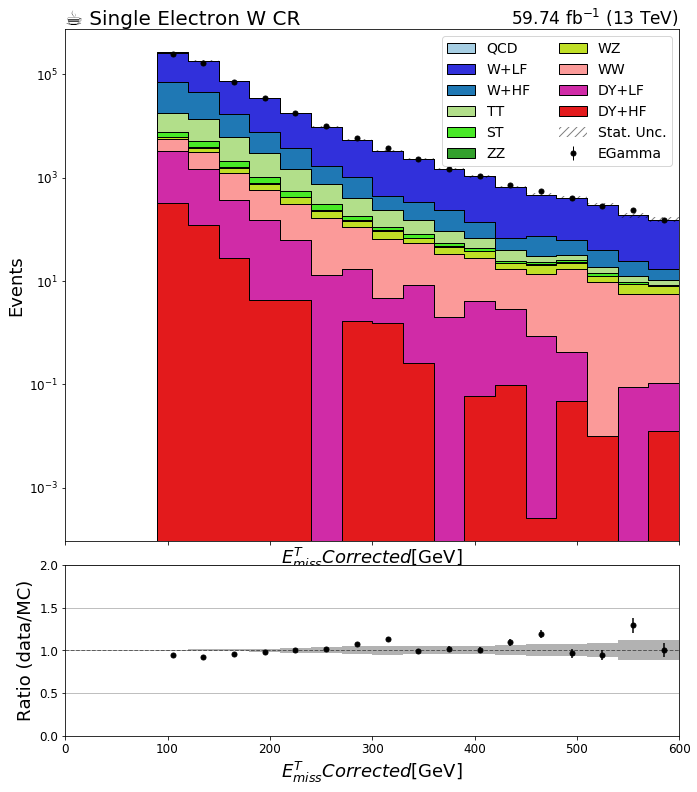

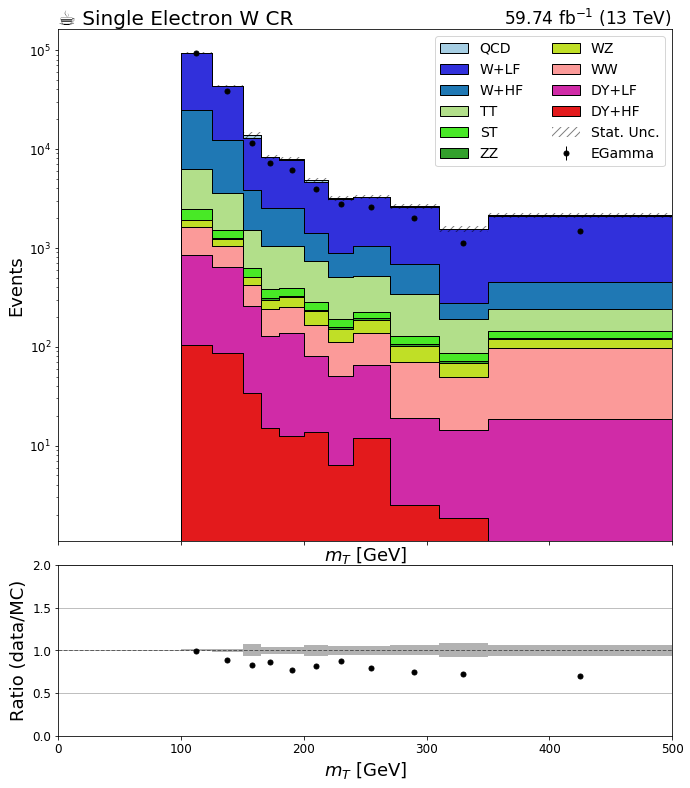

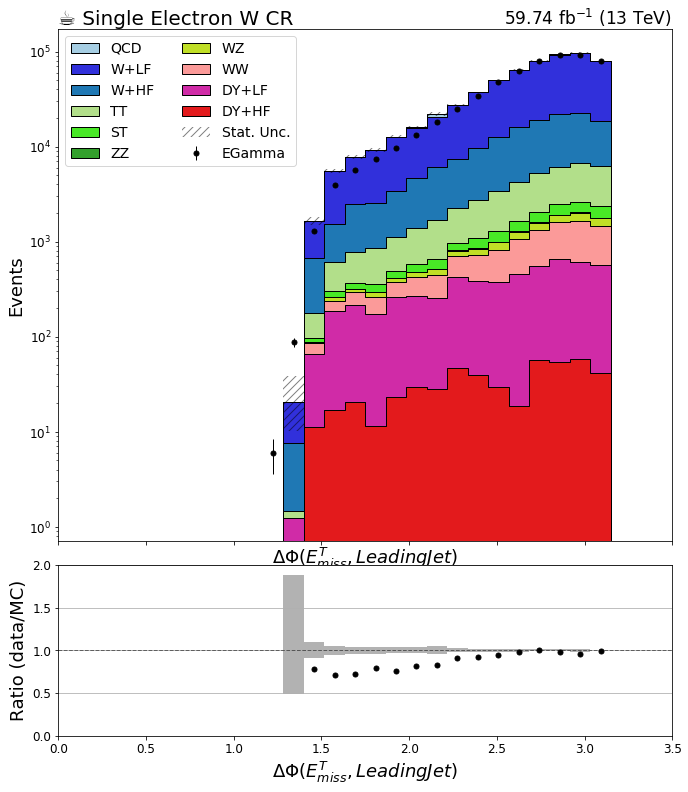

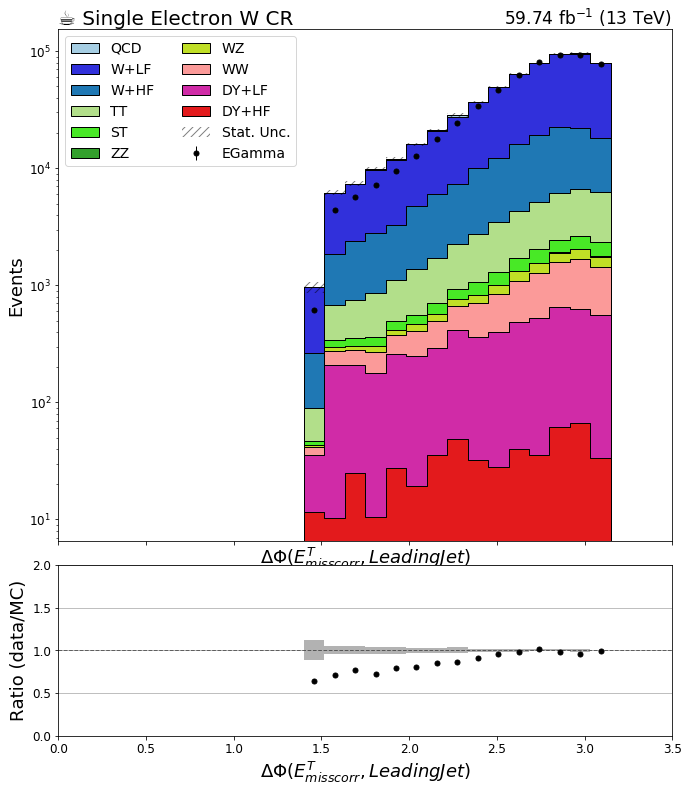

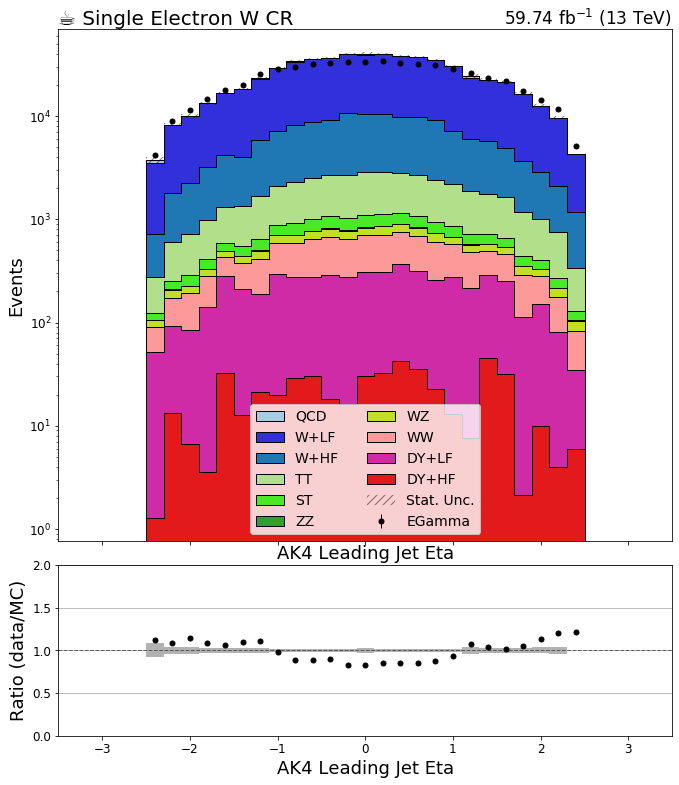

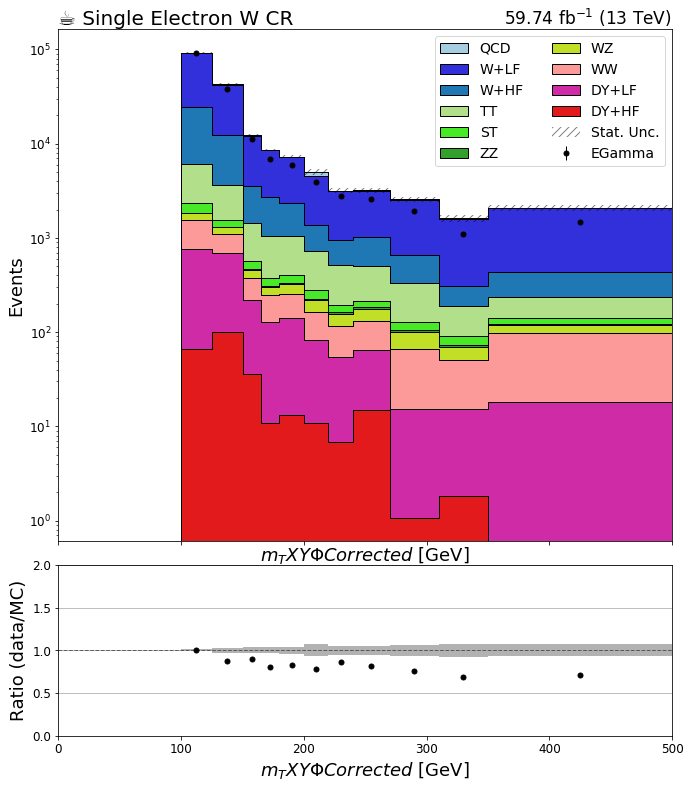

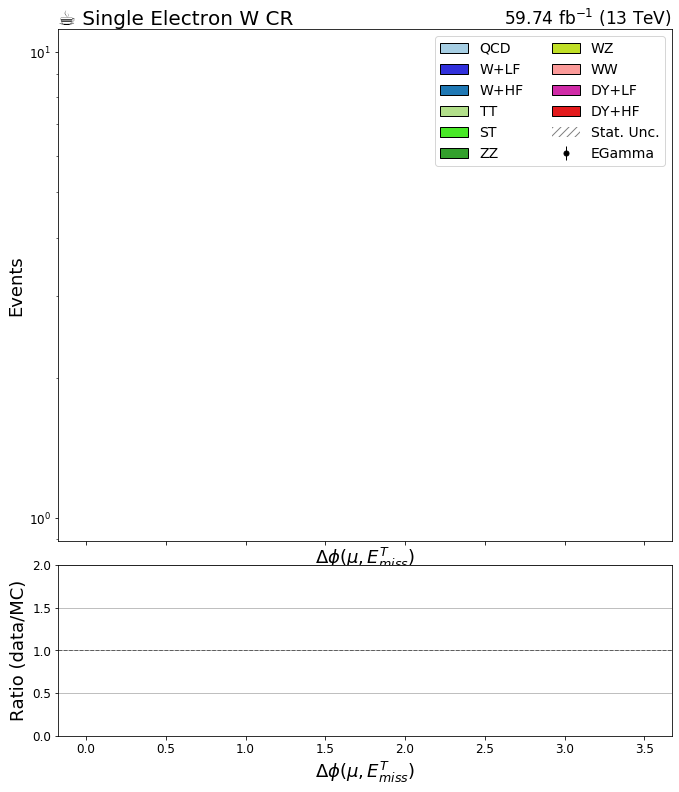

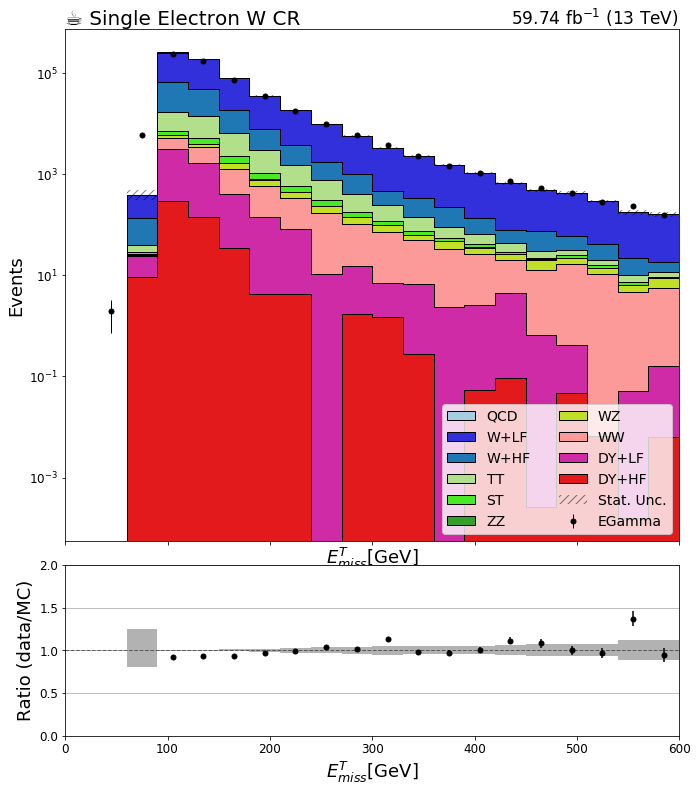

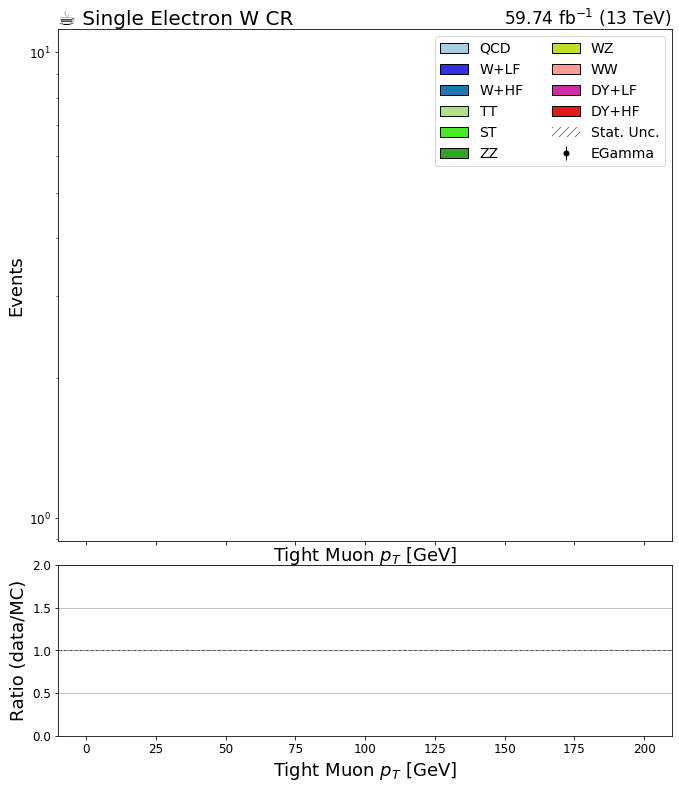

In [3]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

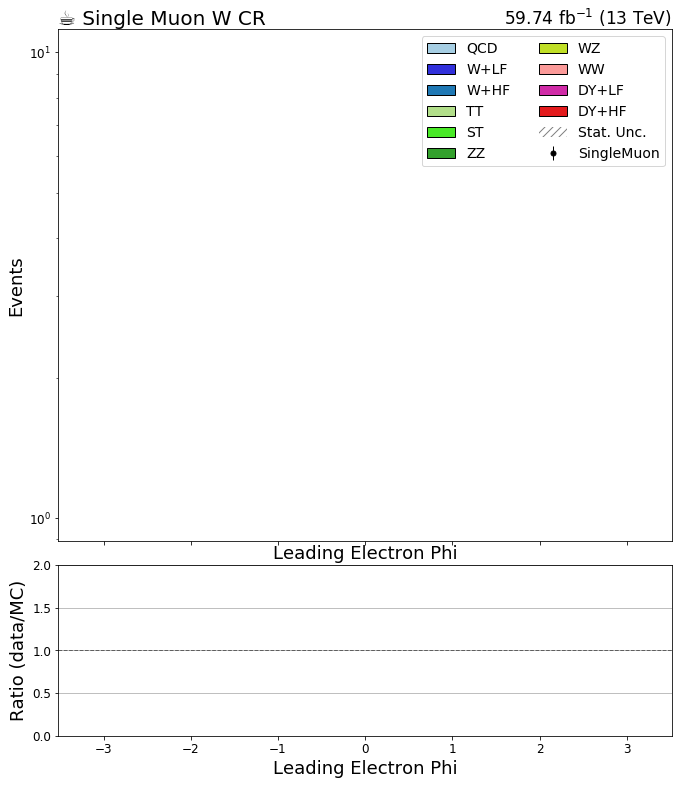

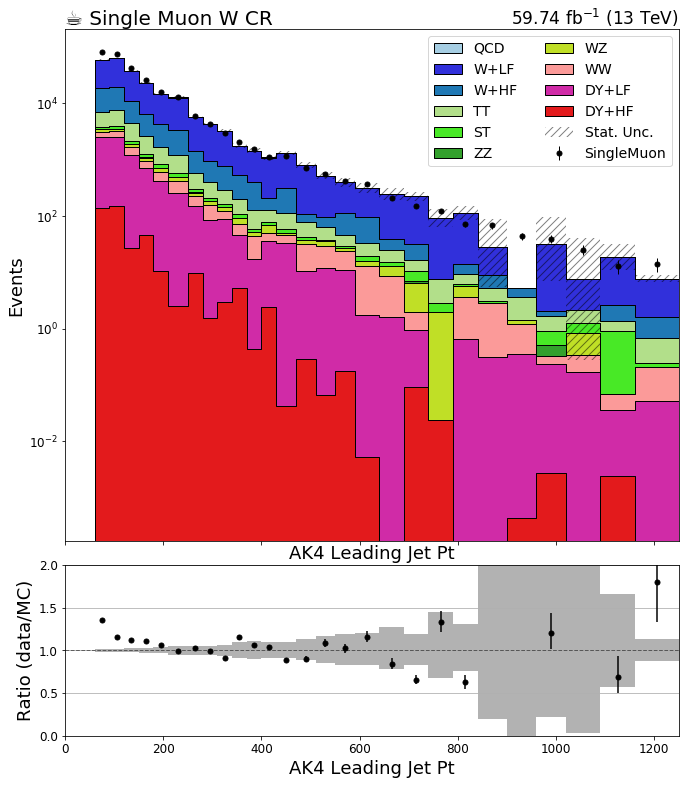

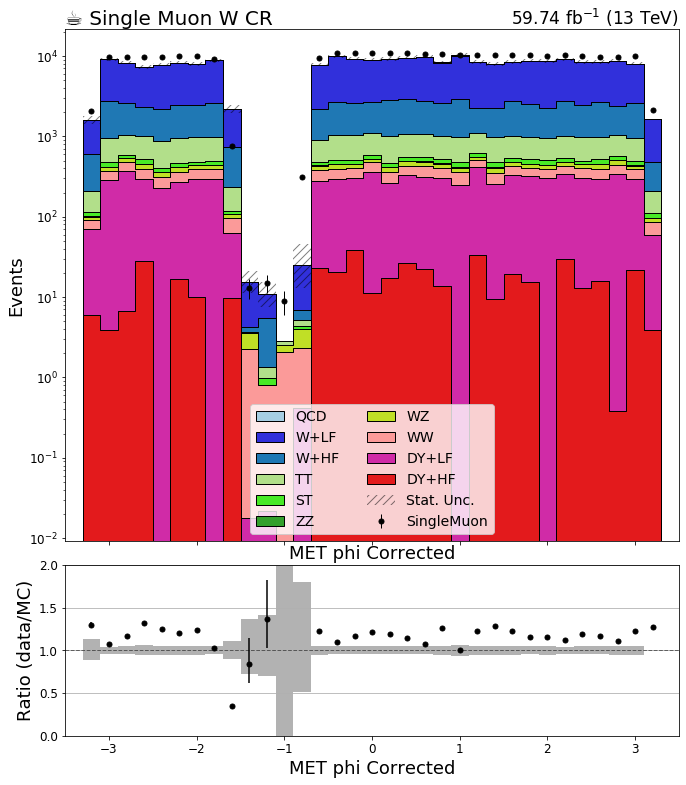

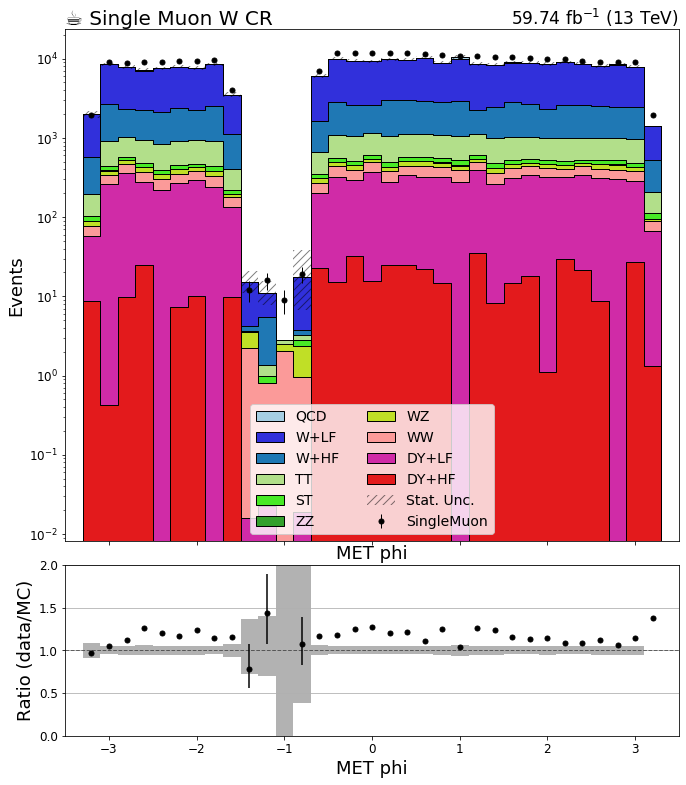

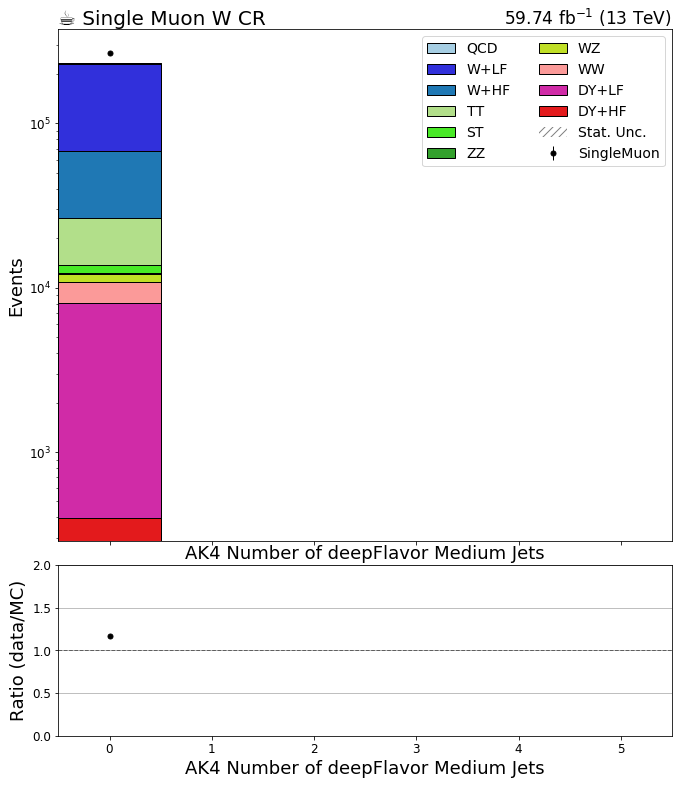

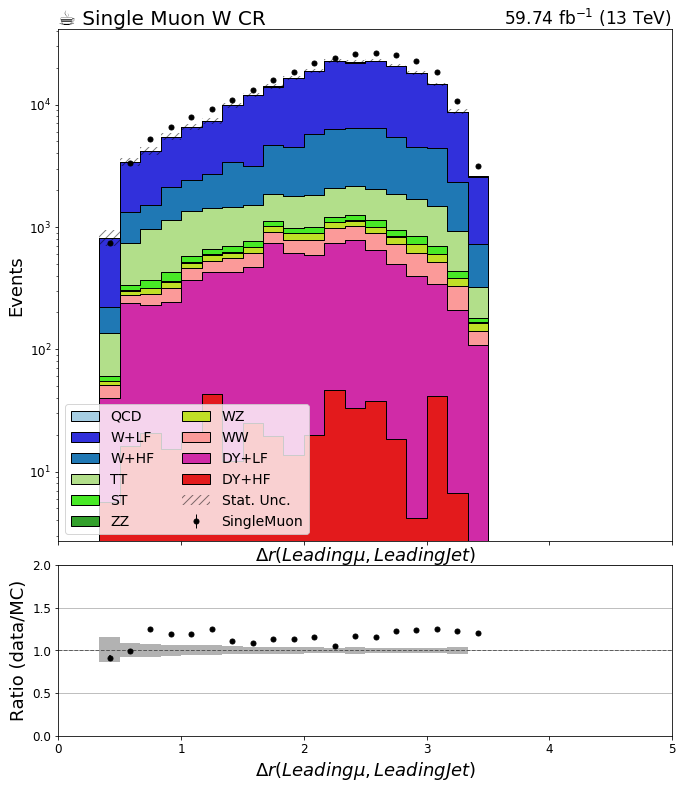

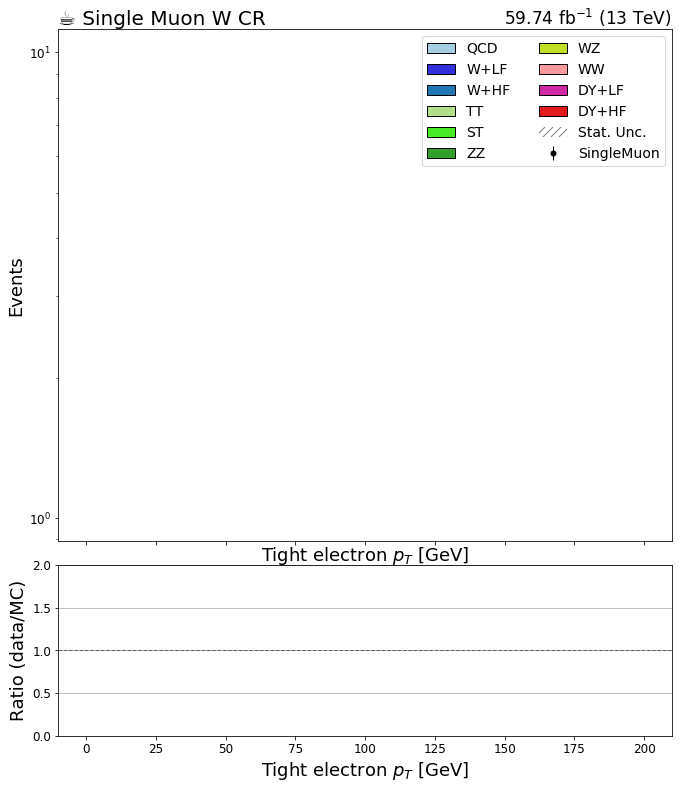

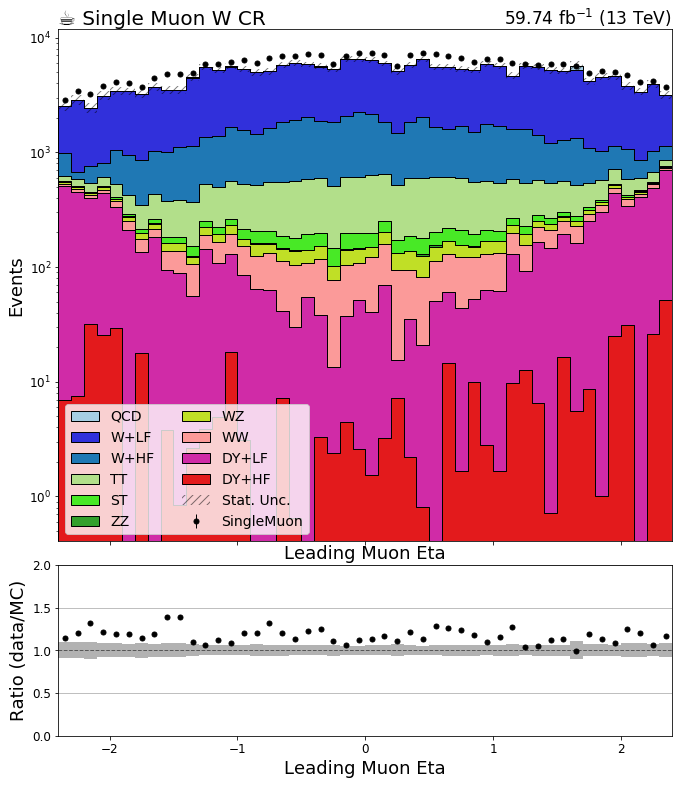

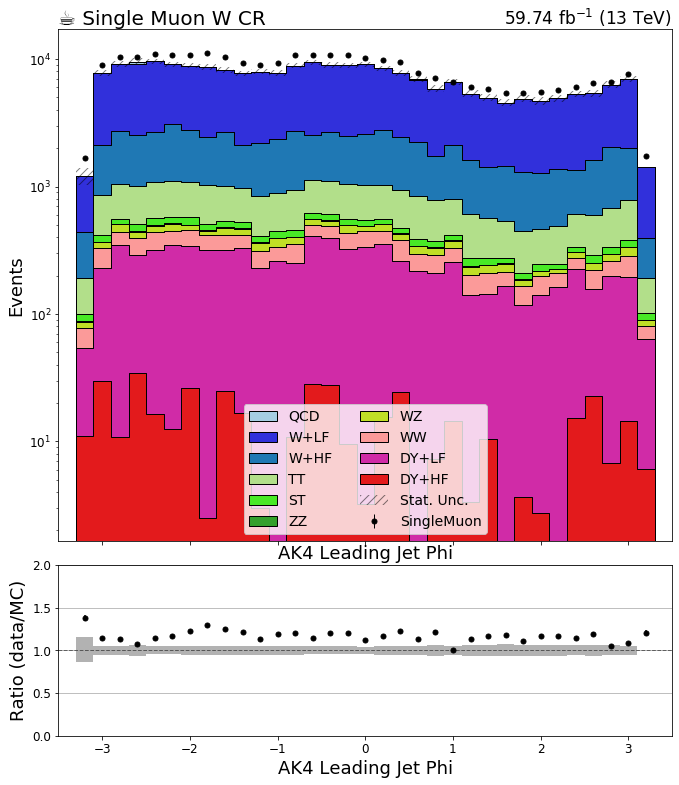

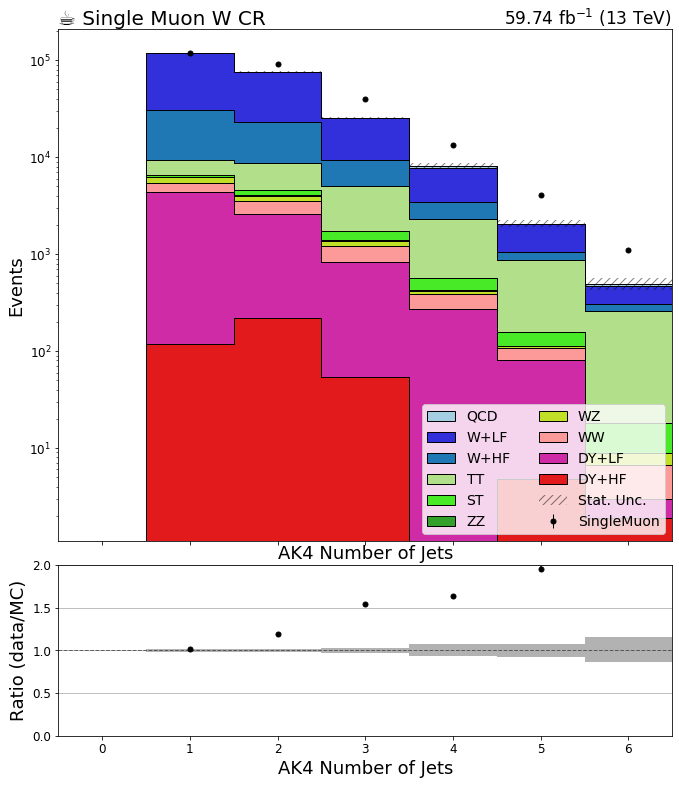

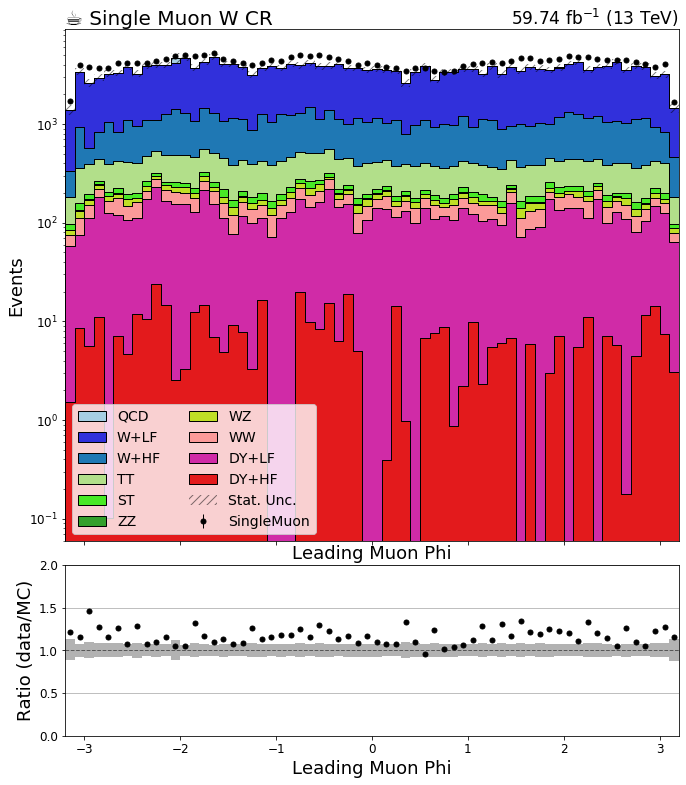

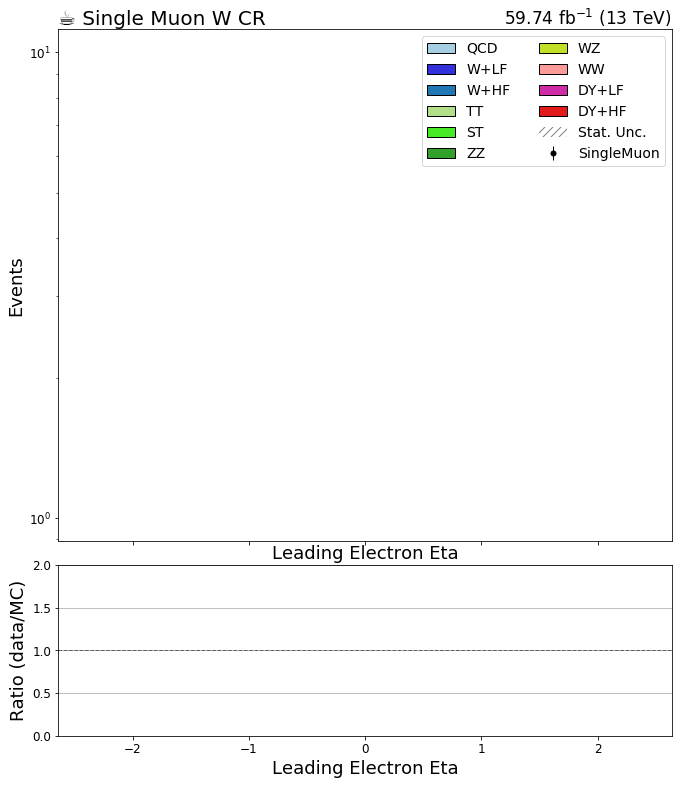

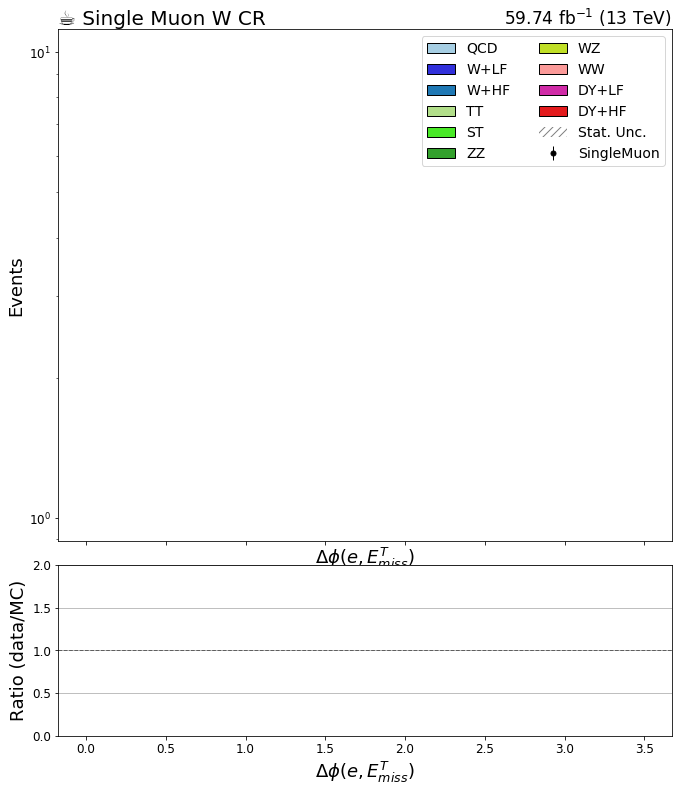

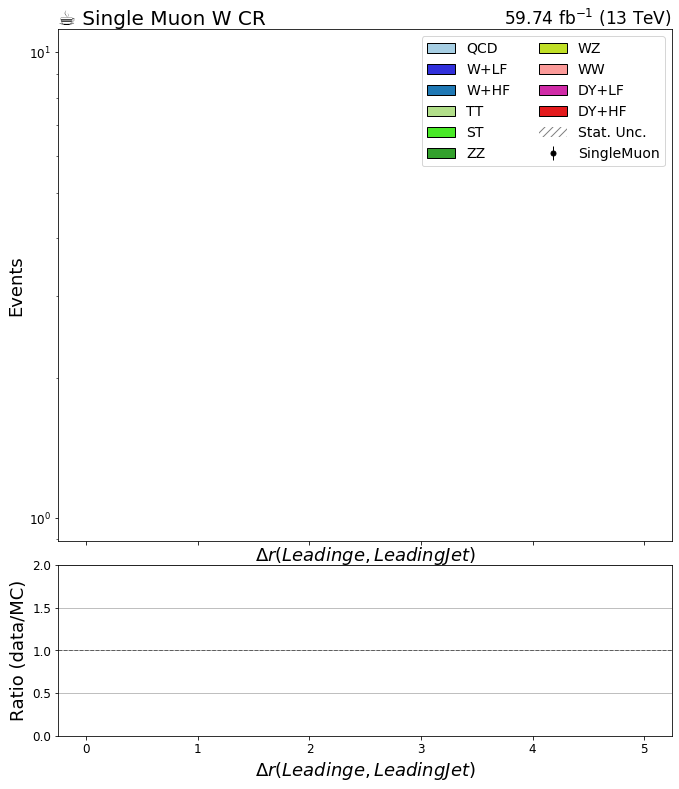

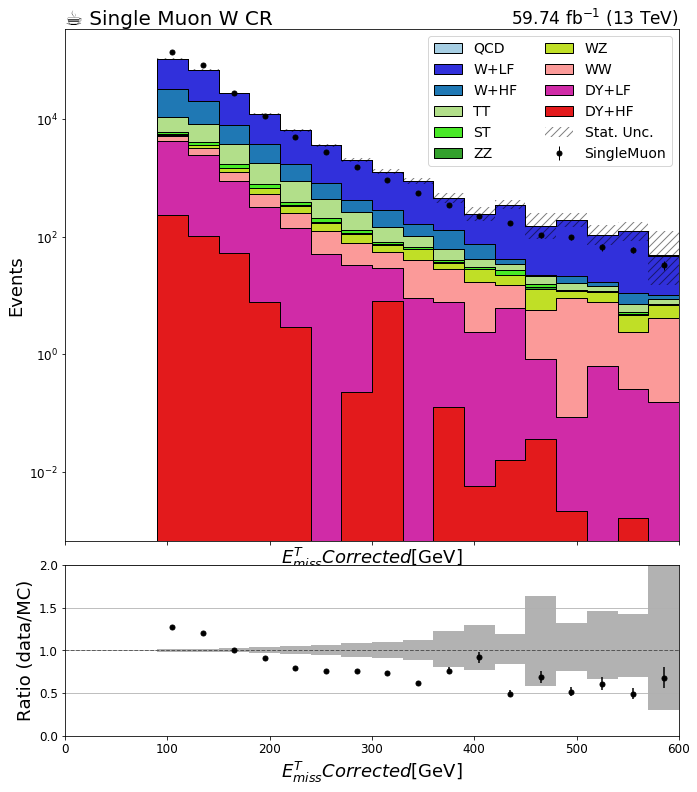

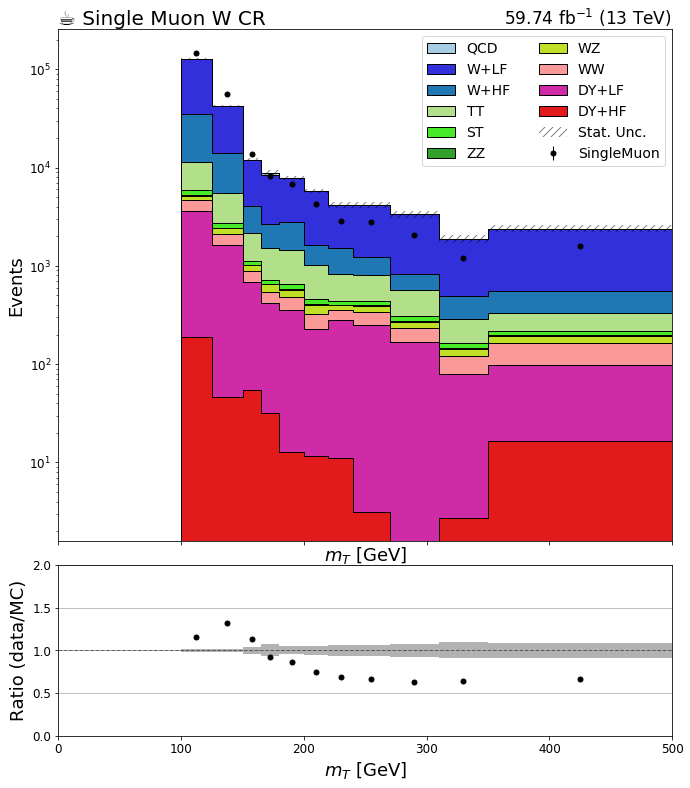

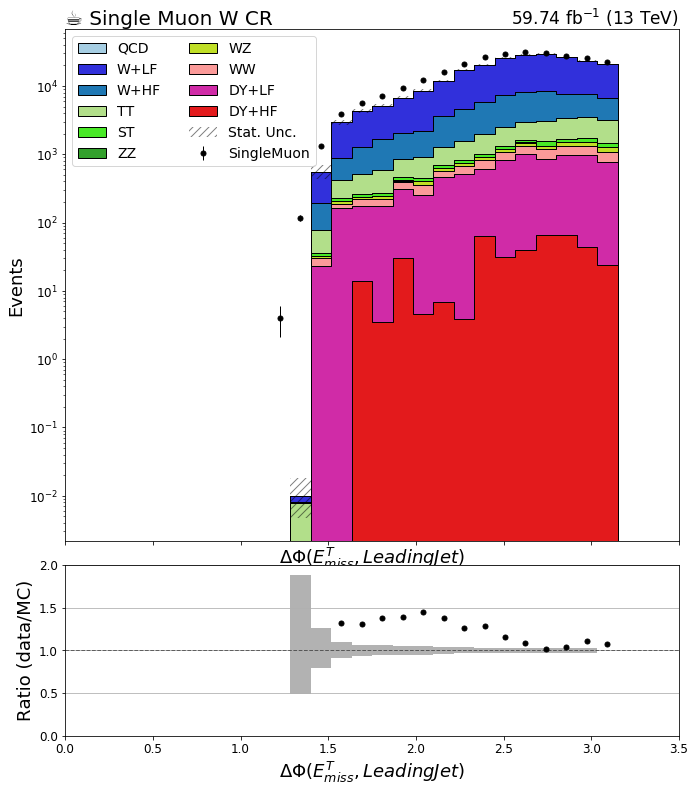

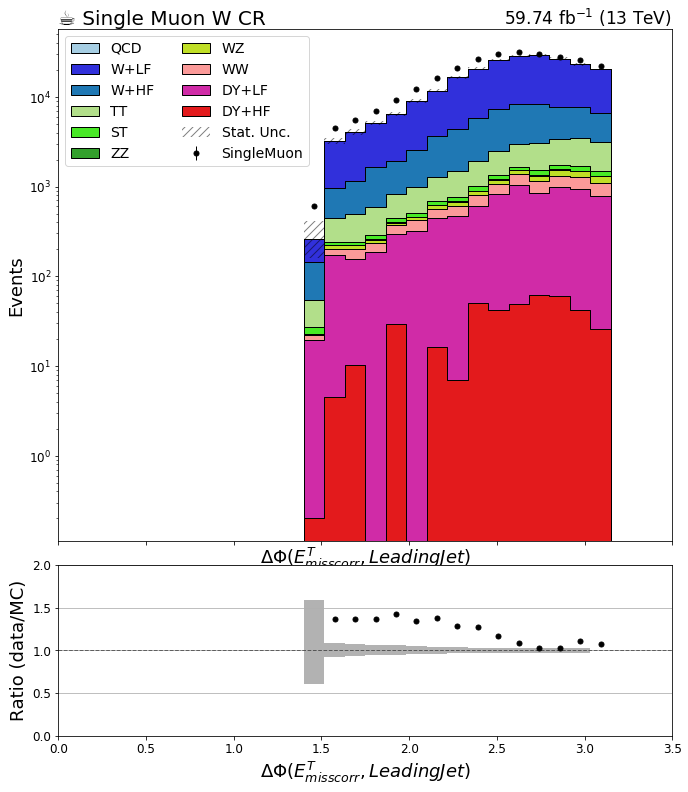

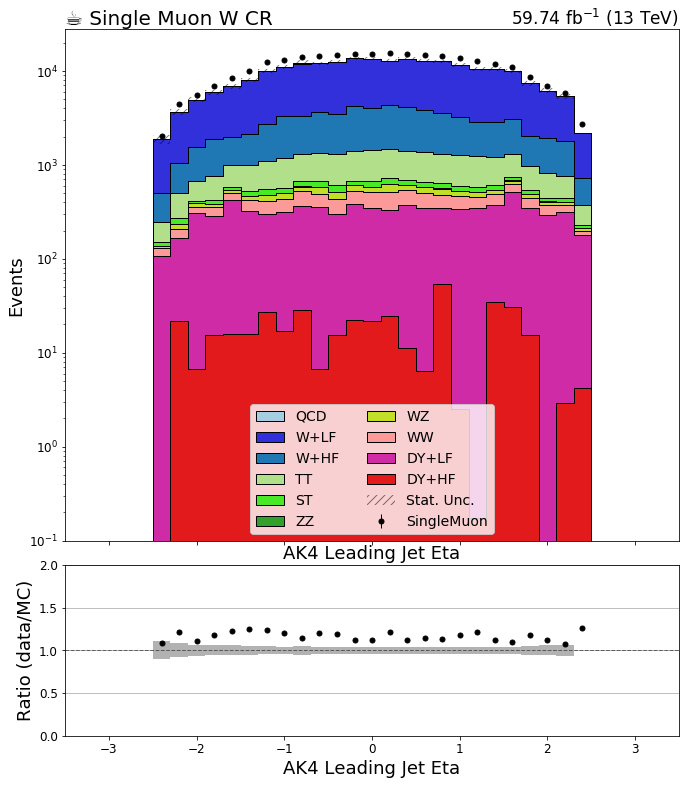

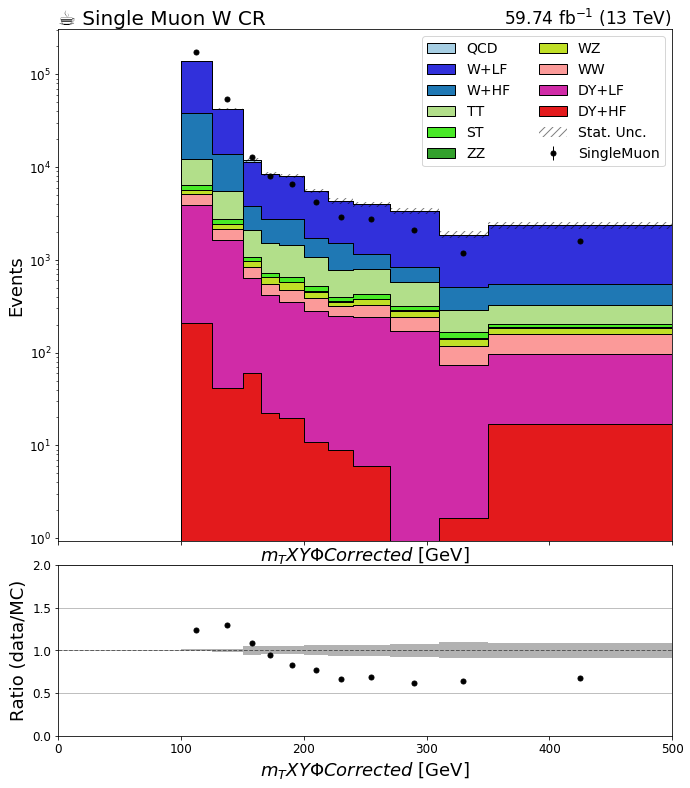

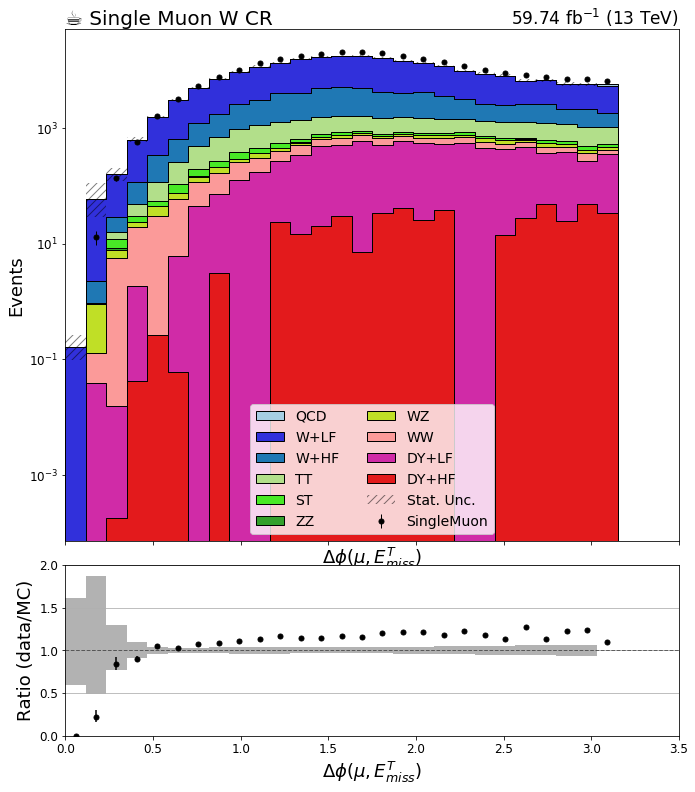

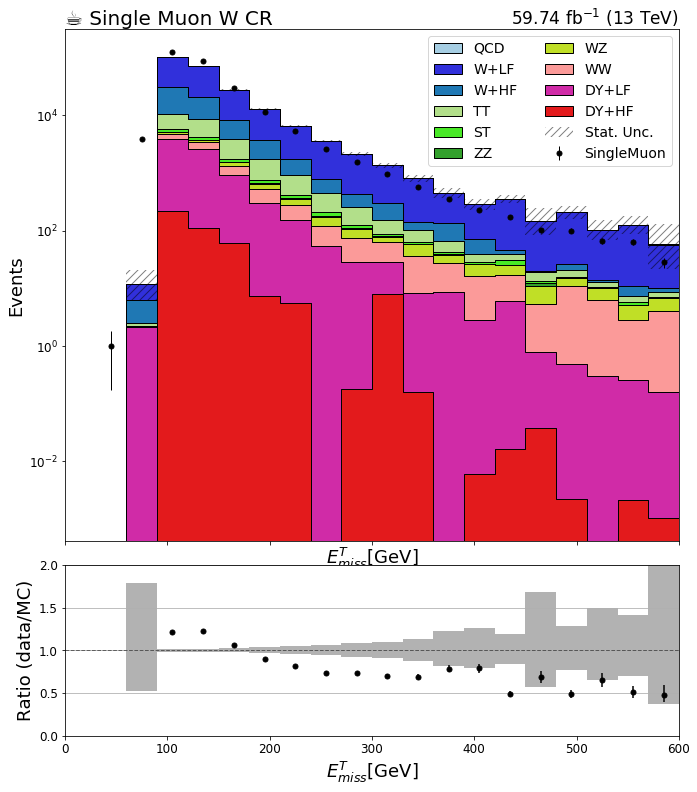

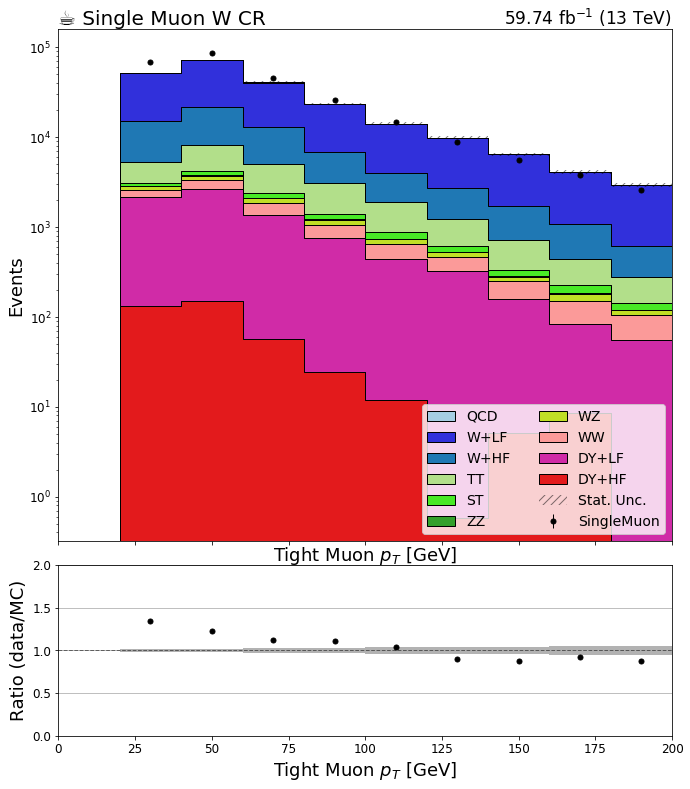

In [3]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

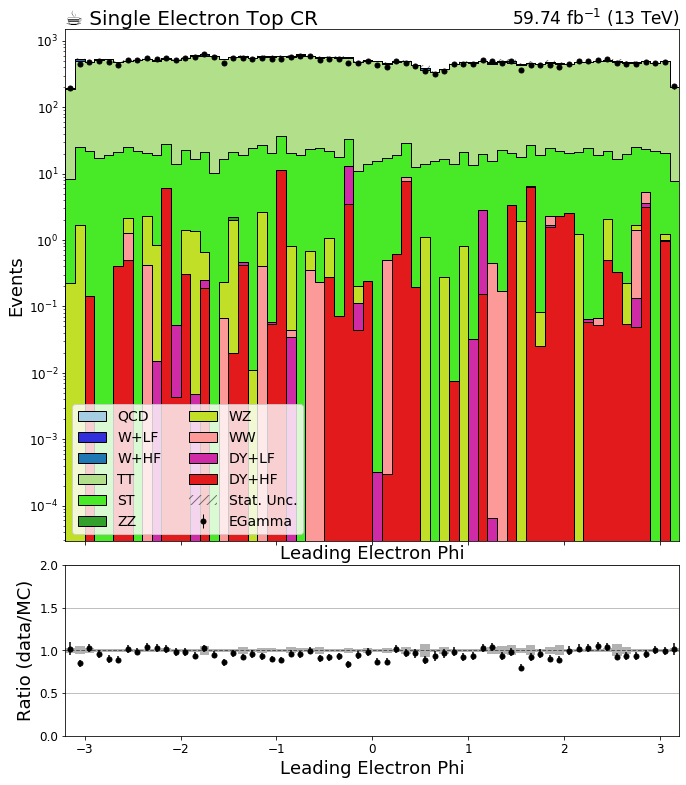

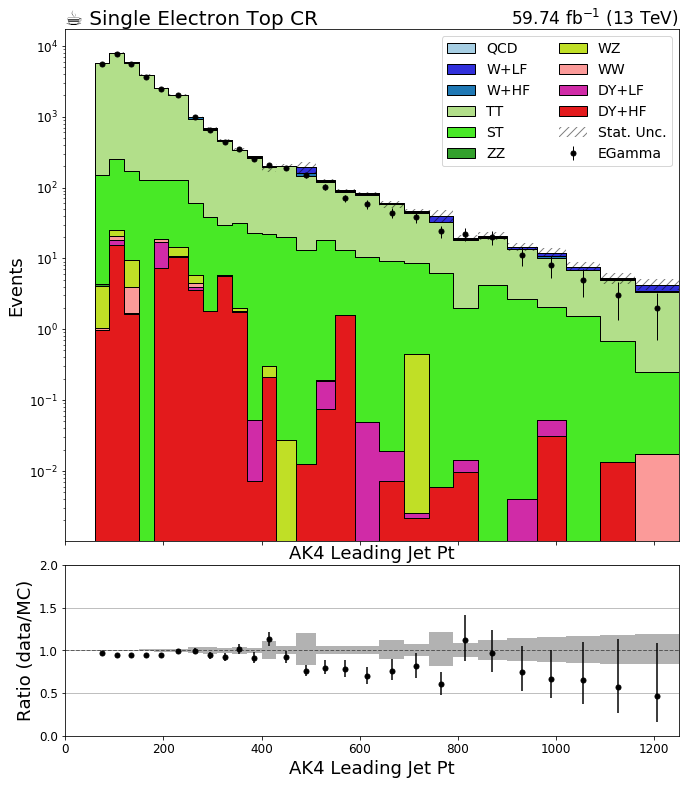

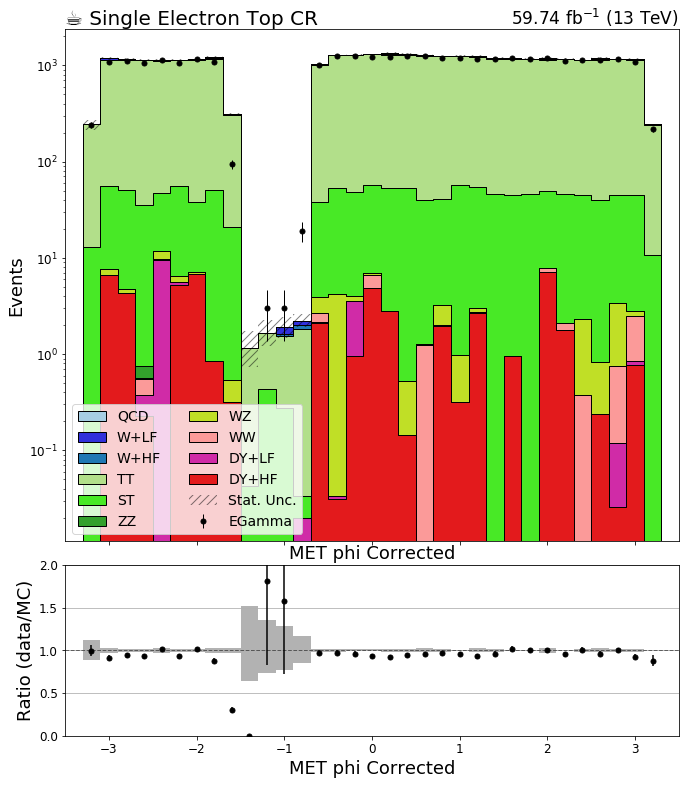

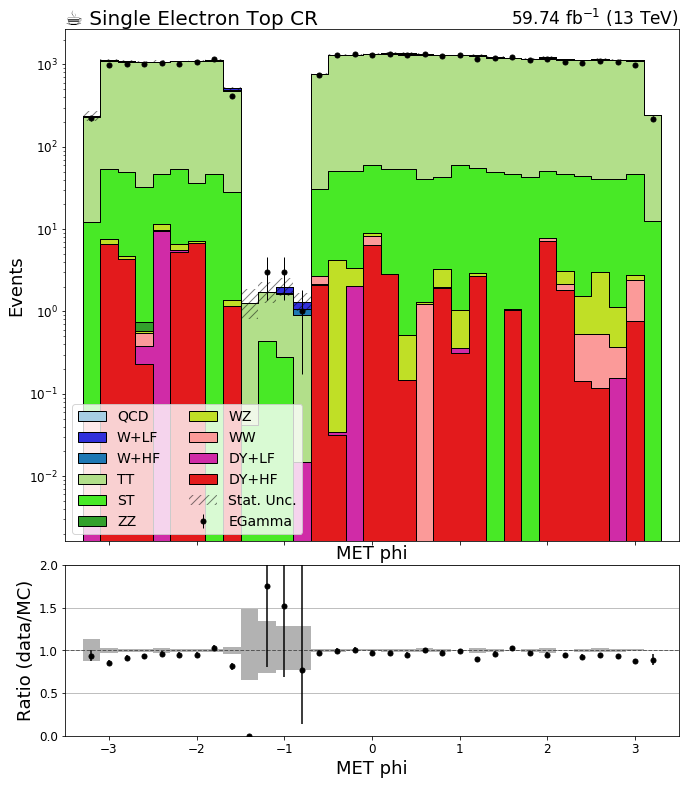

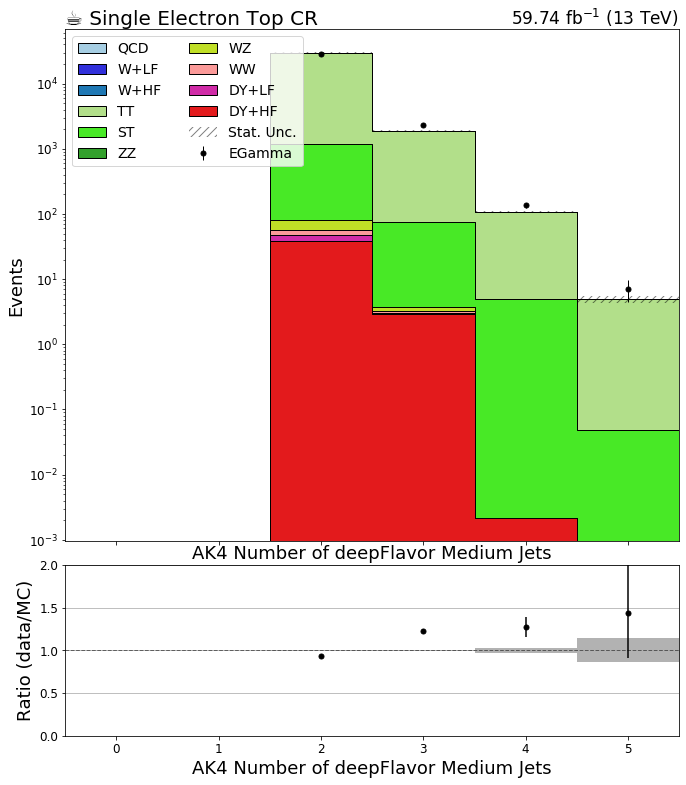

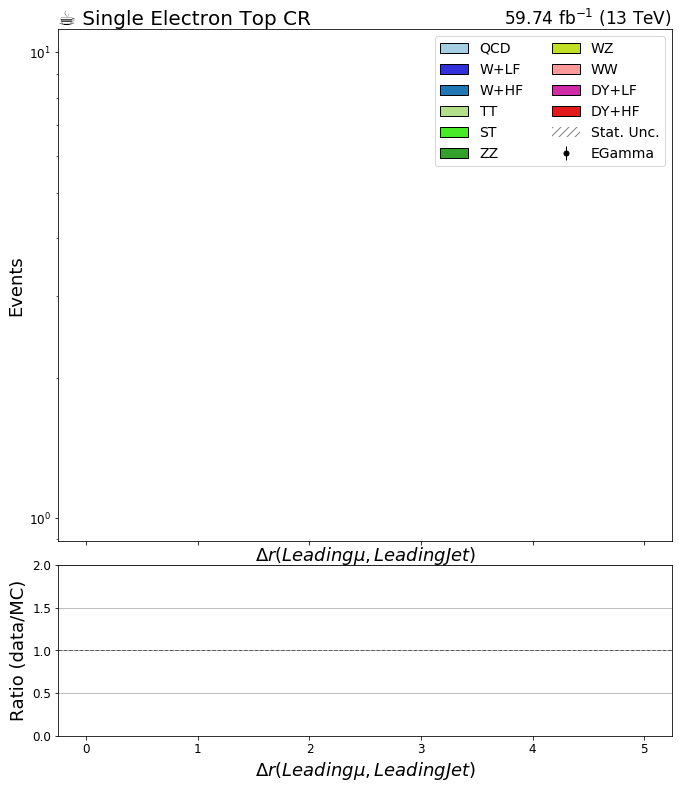

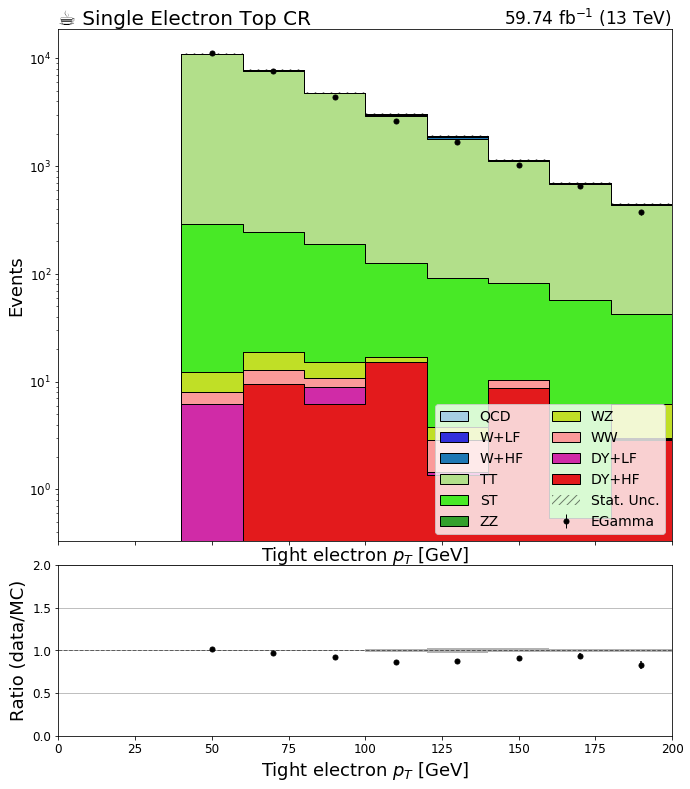

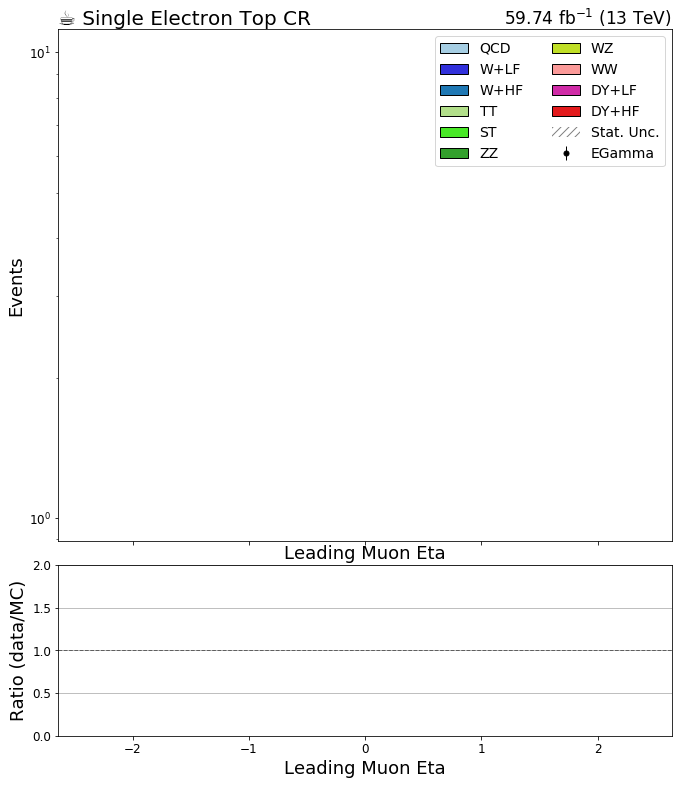

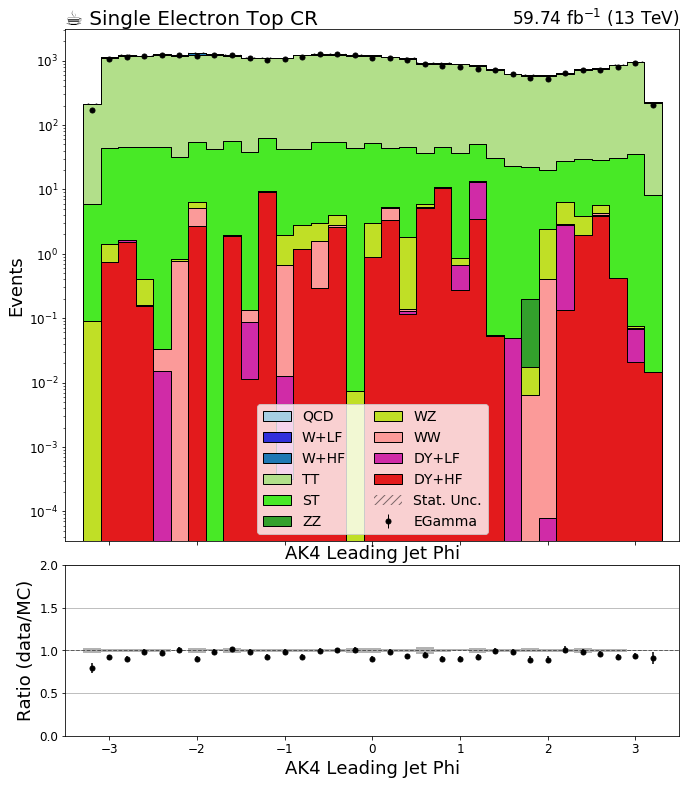

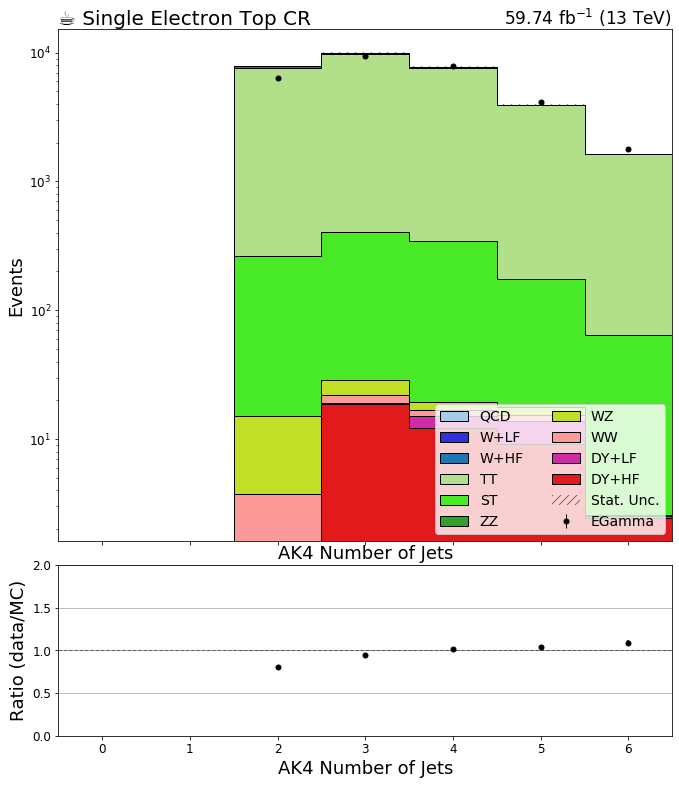

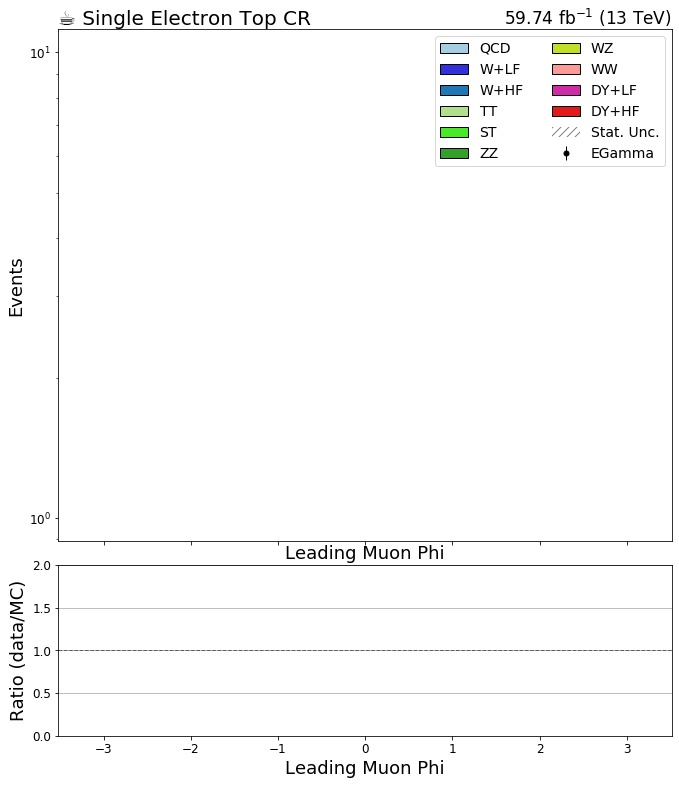

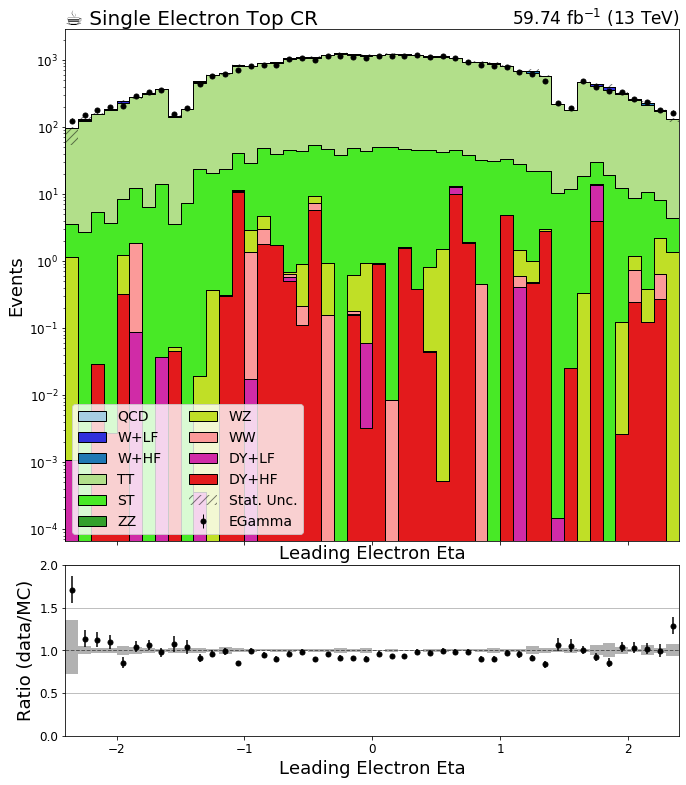

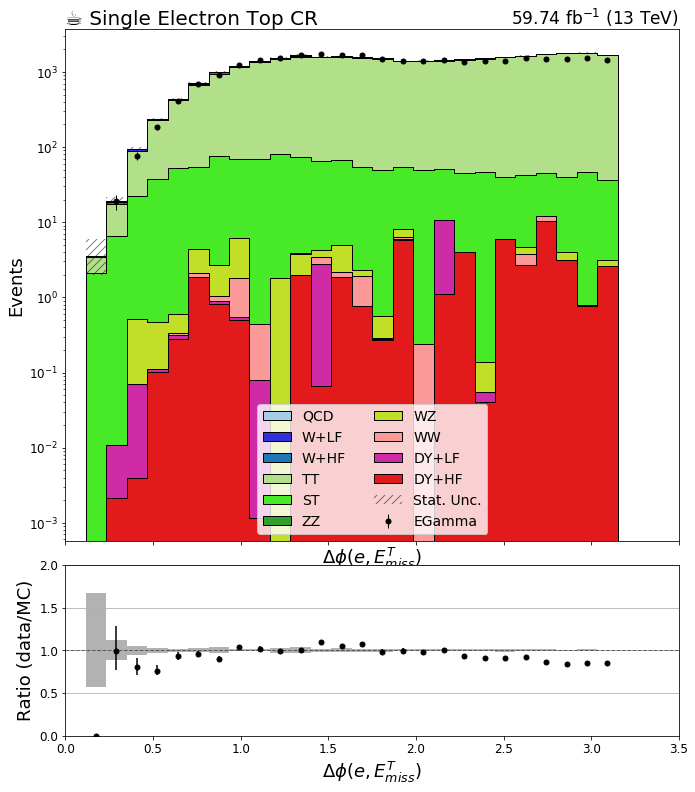

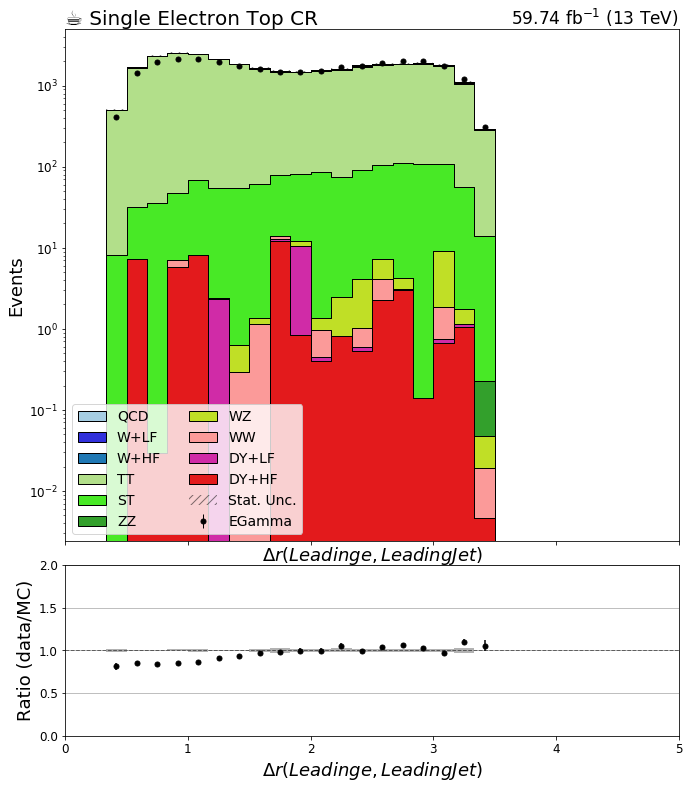

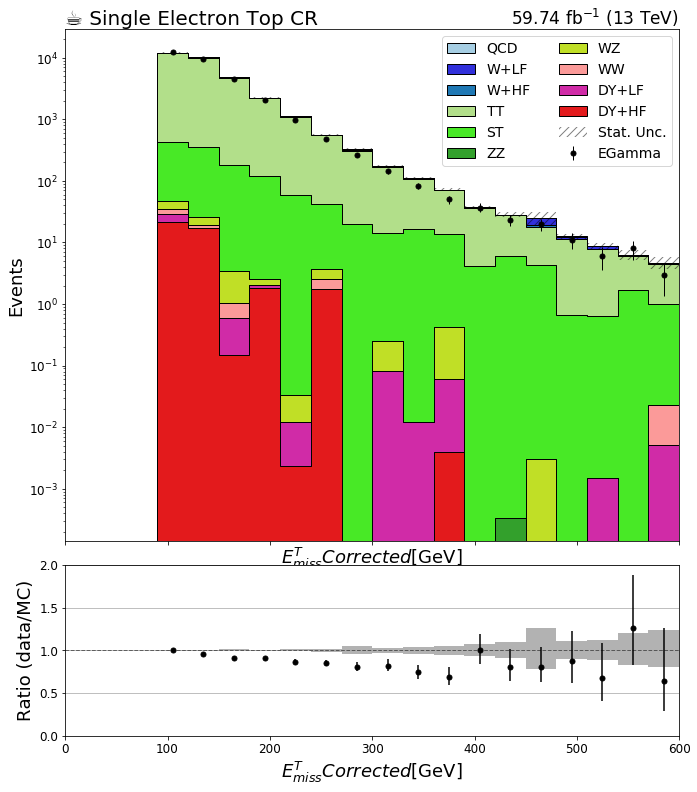

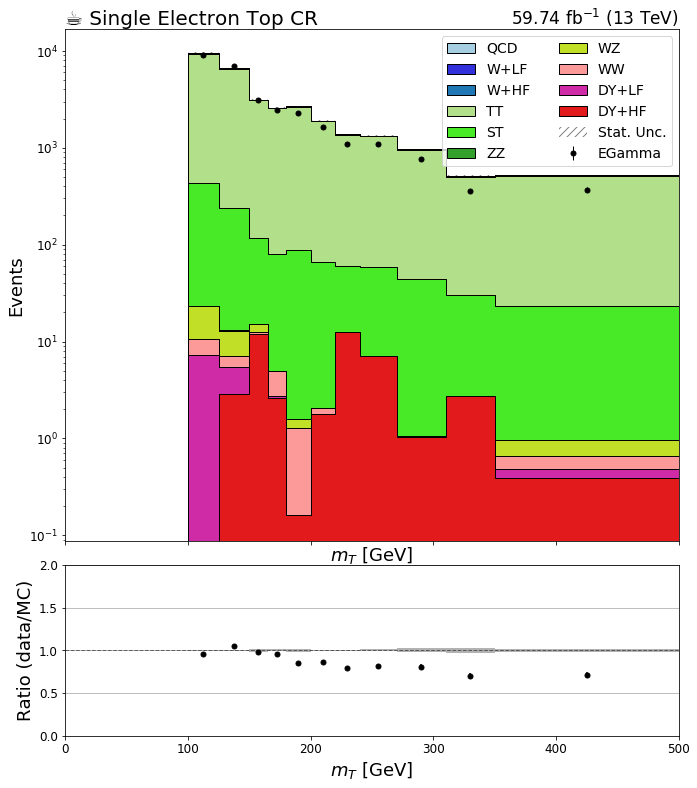

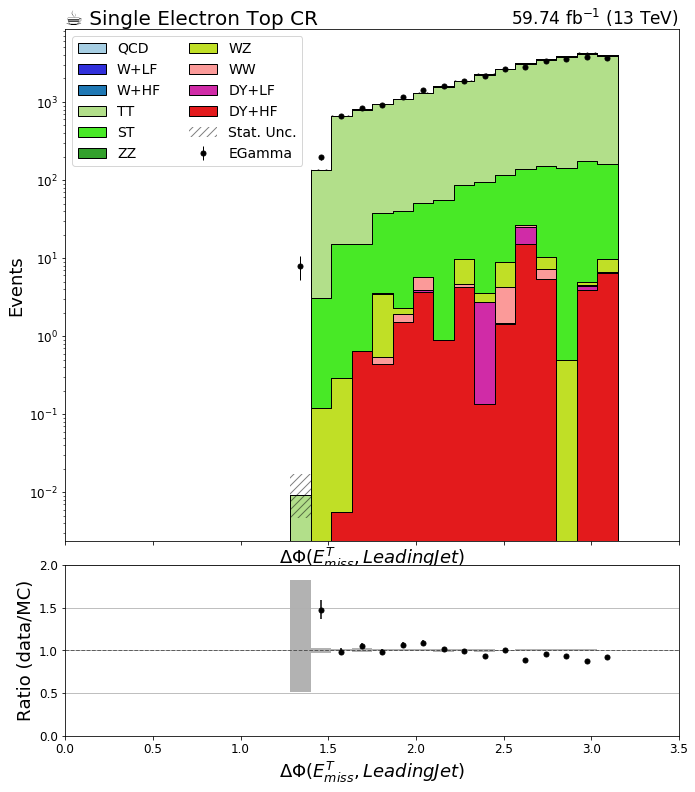

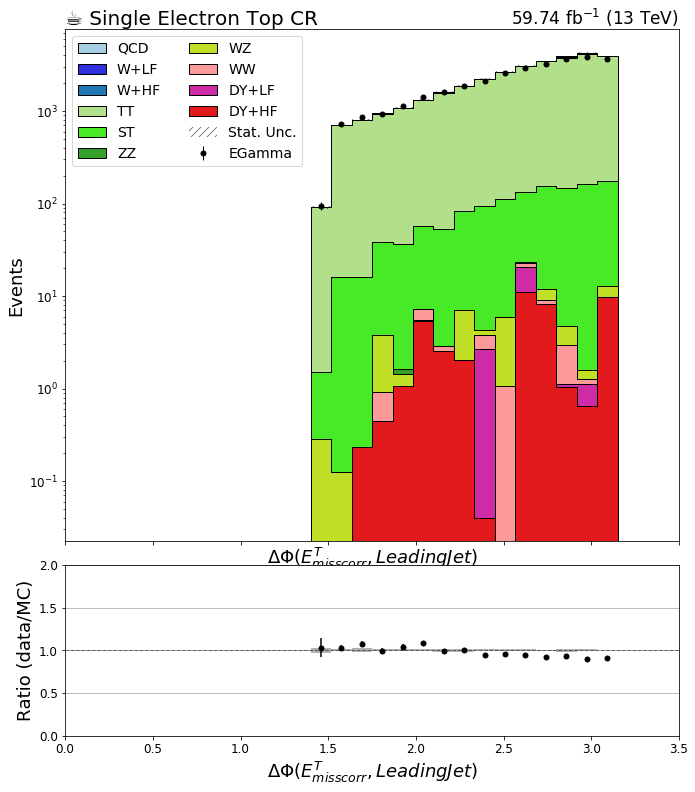

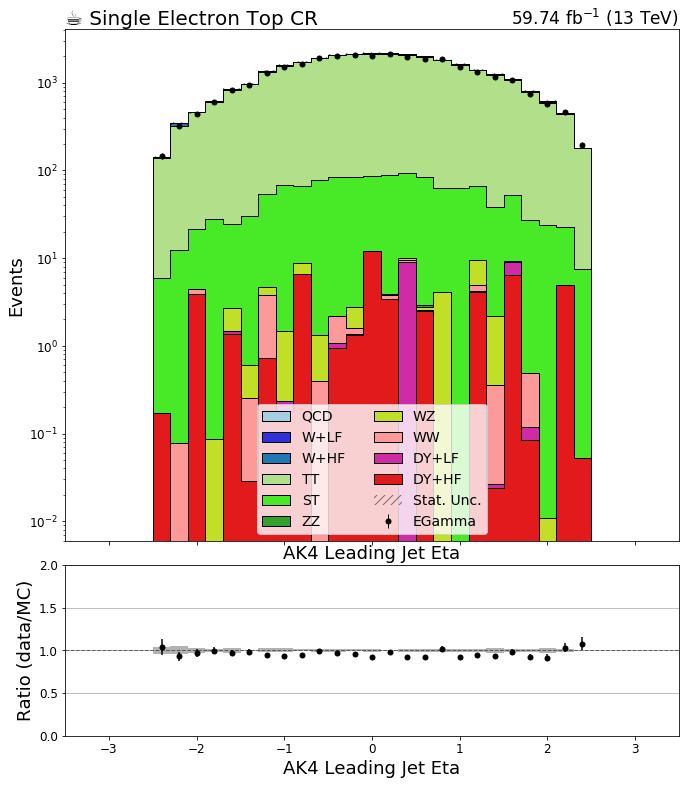

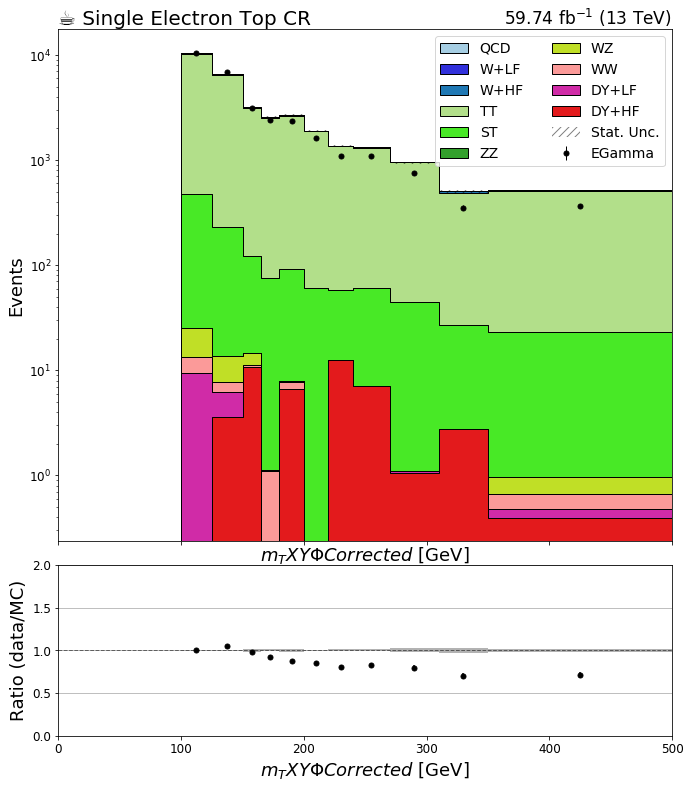

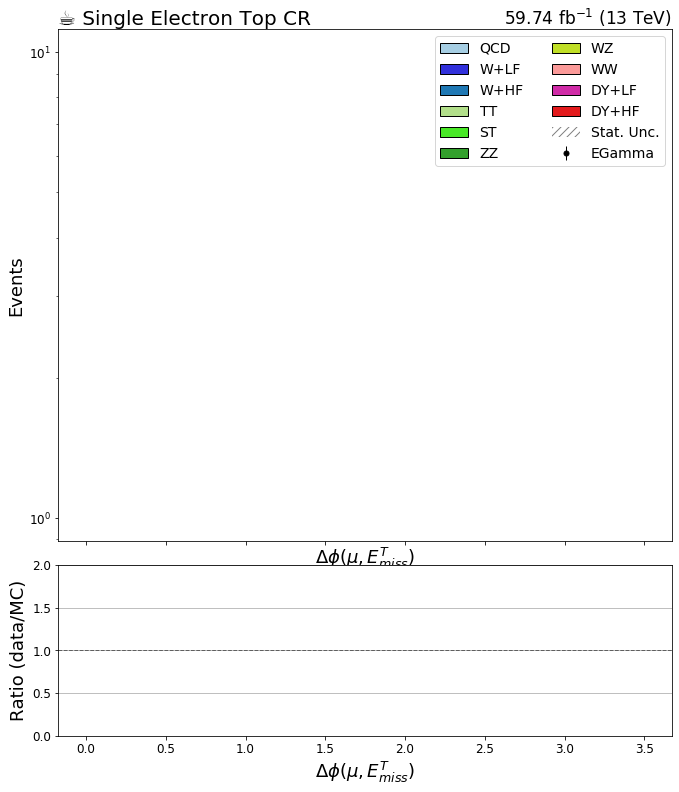

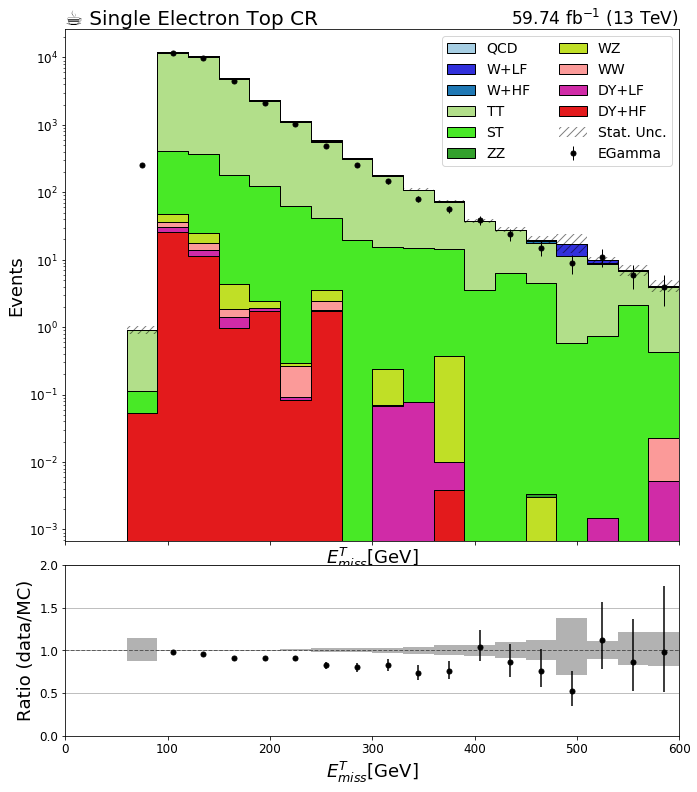

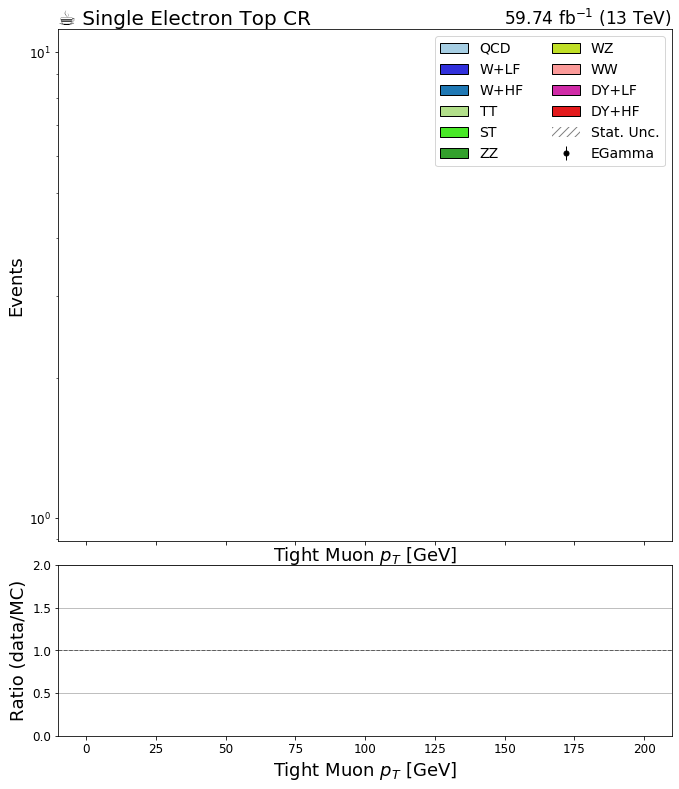

In [6]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

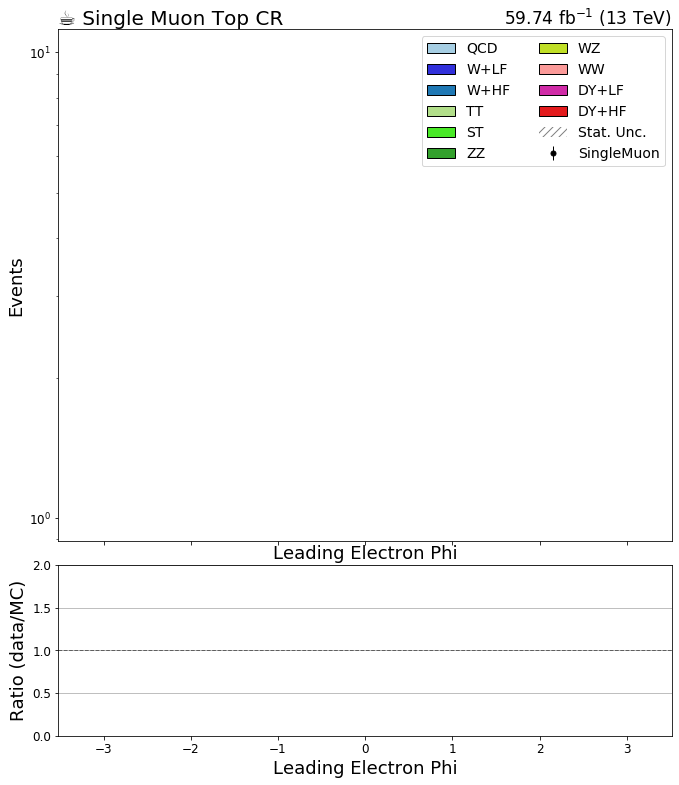

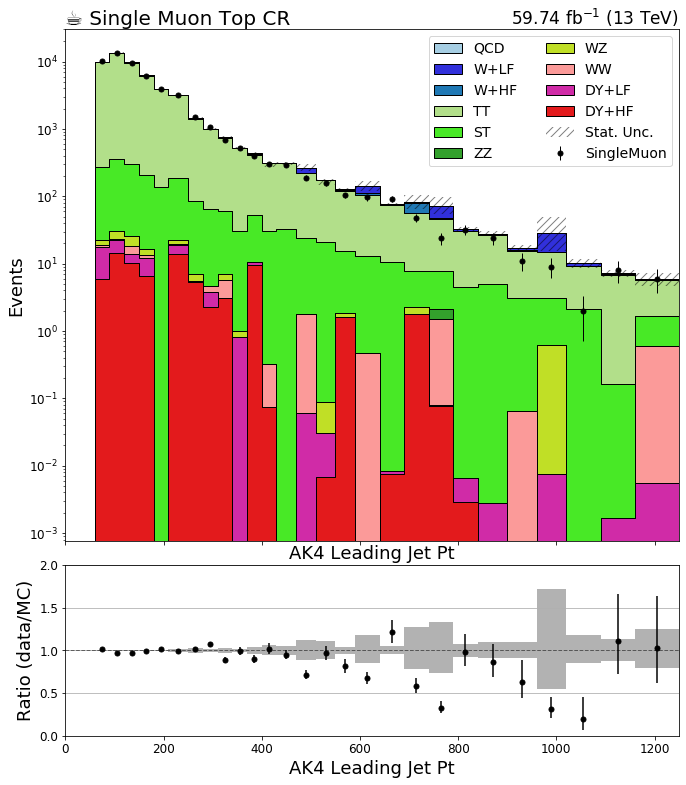

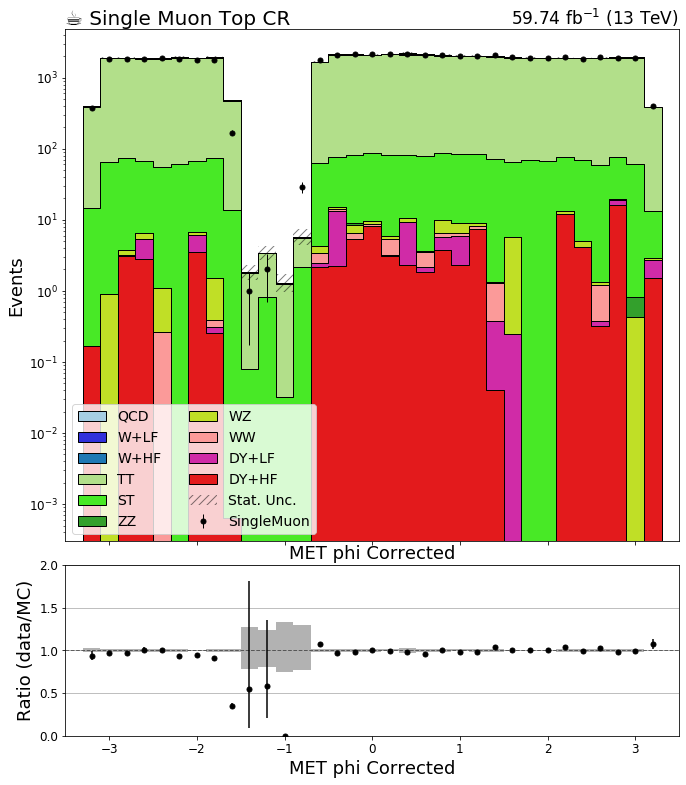

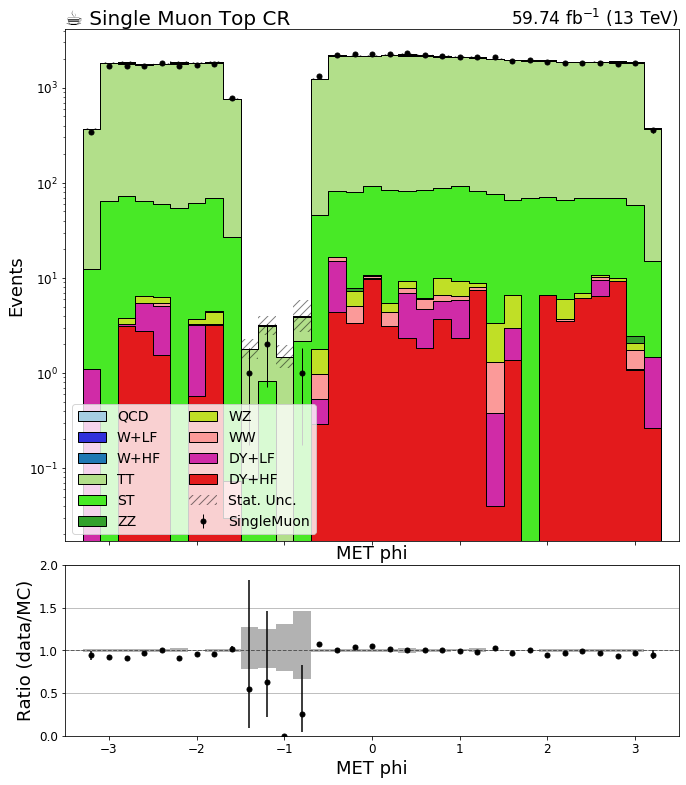

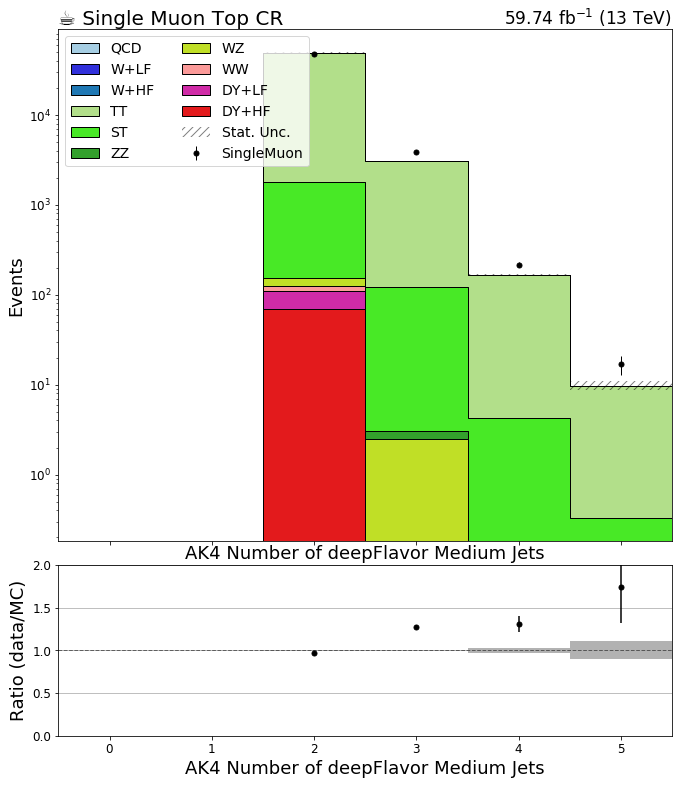

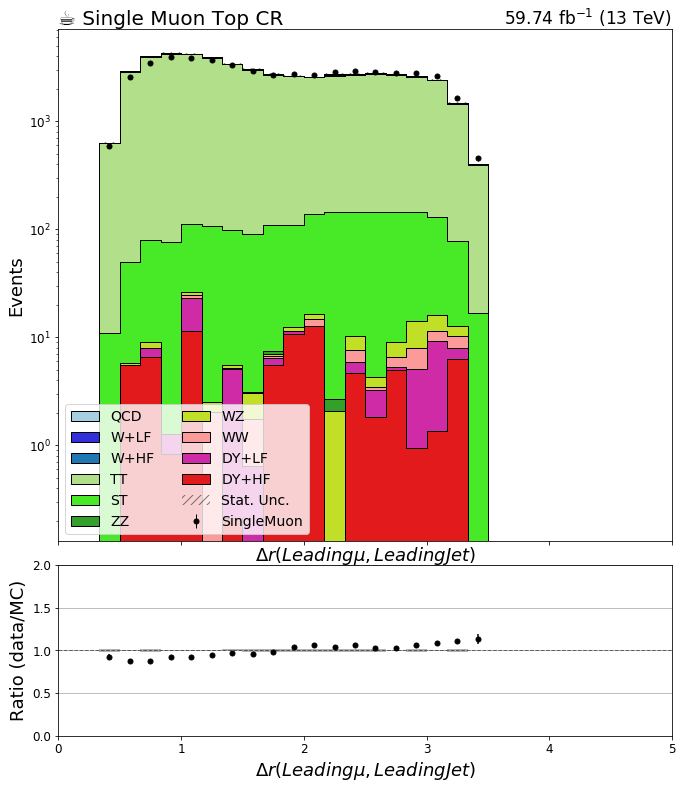

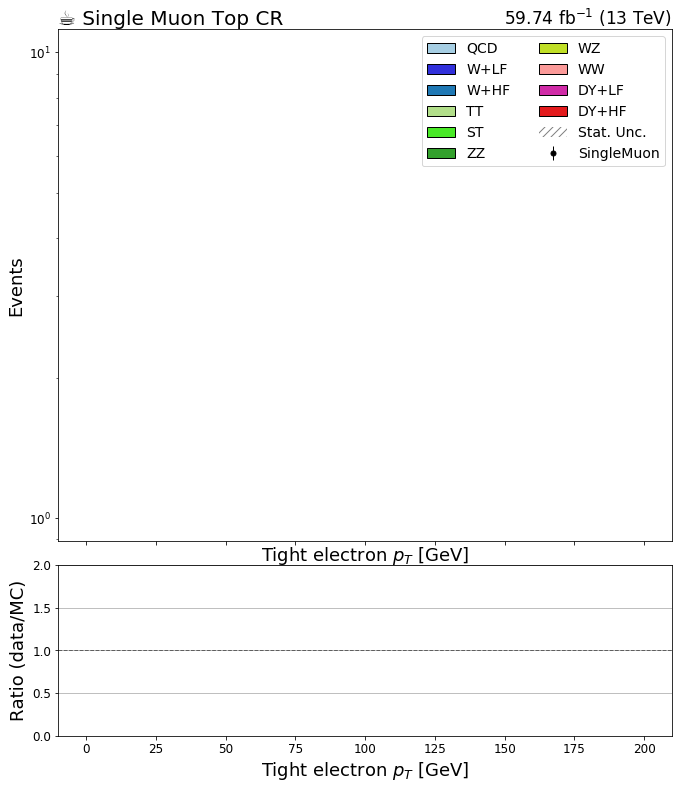

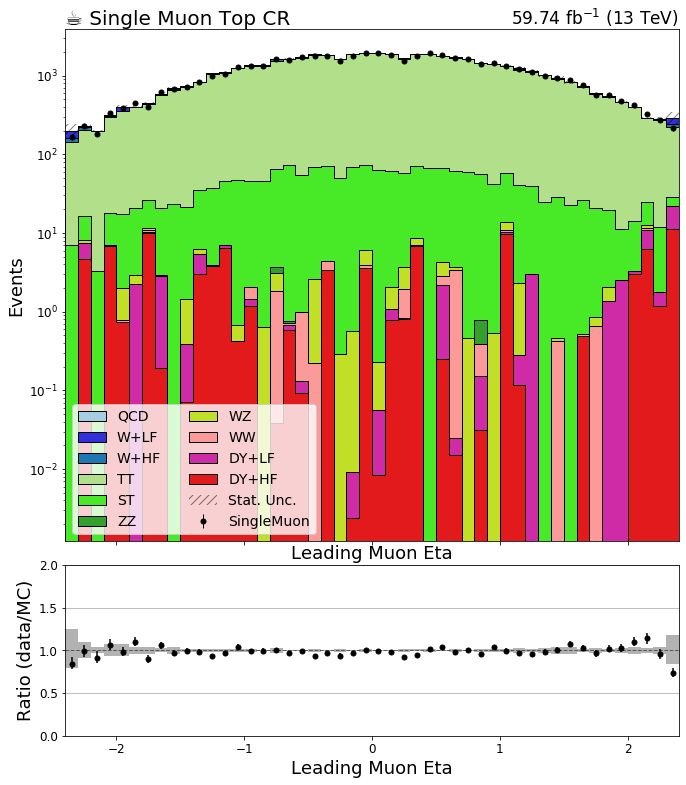

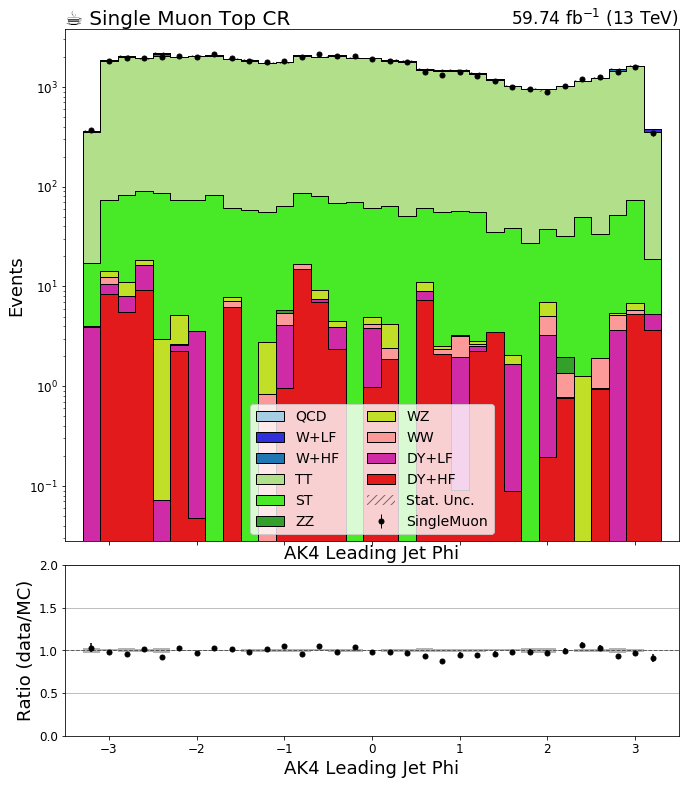

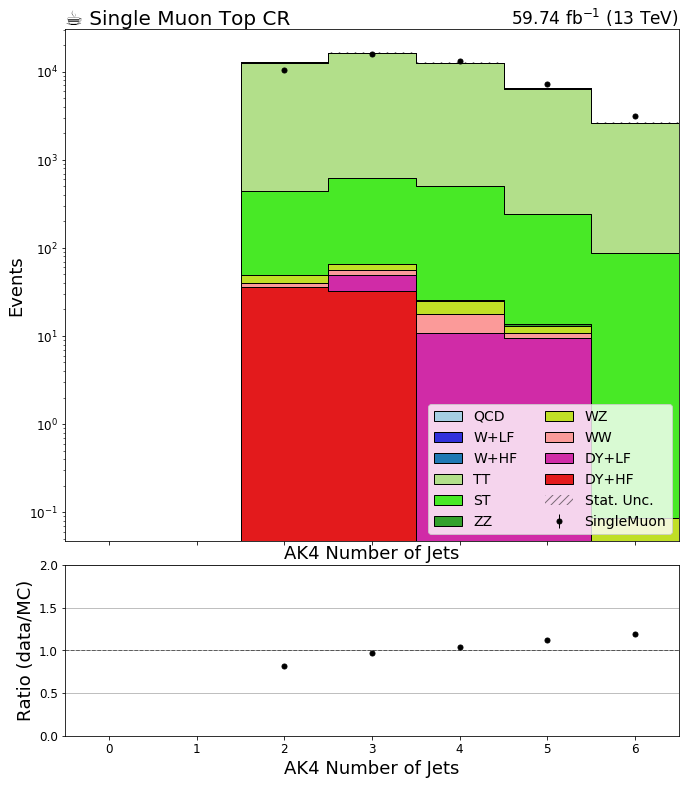

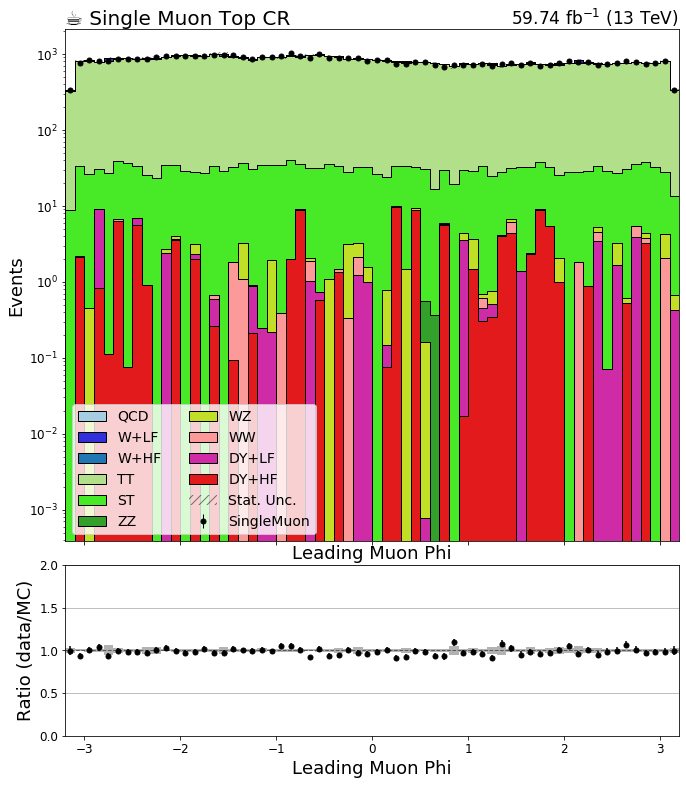

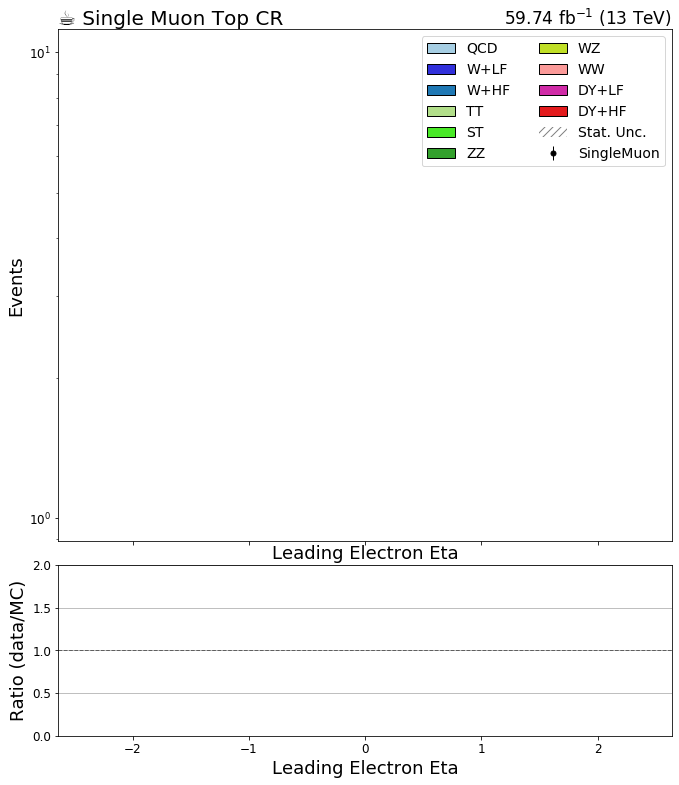

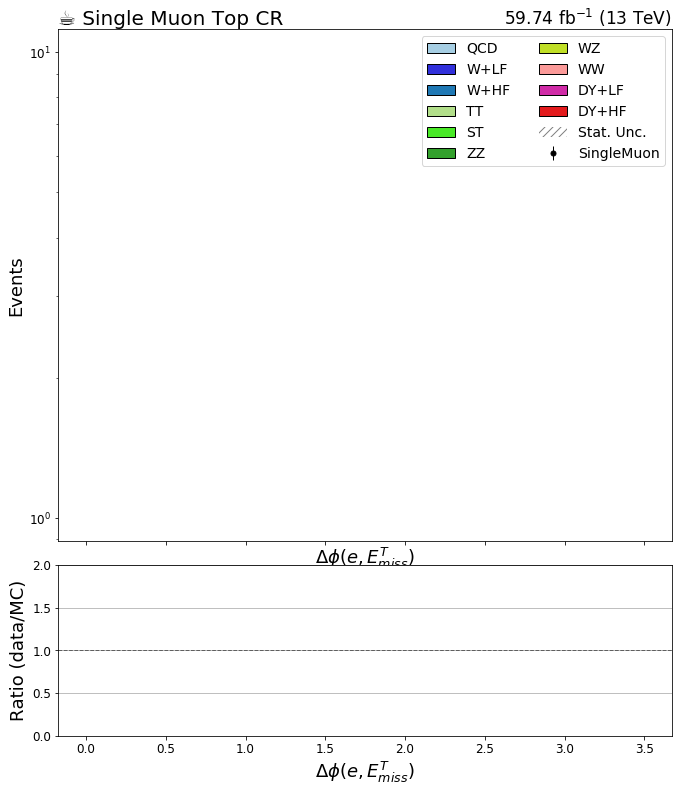

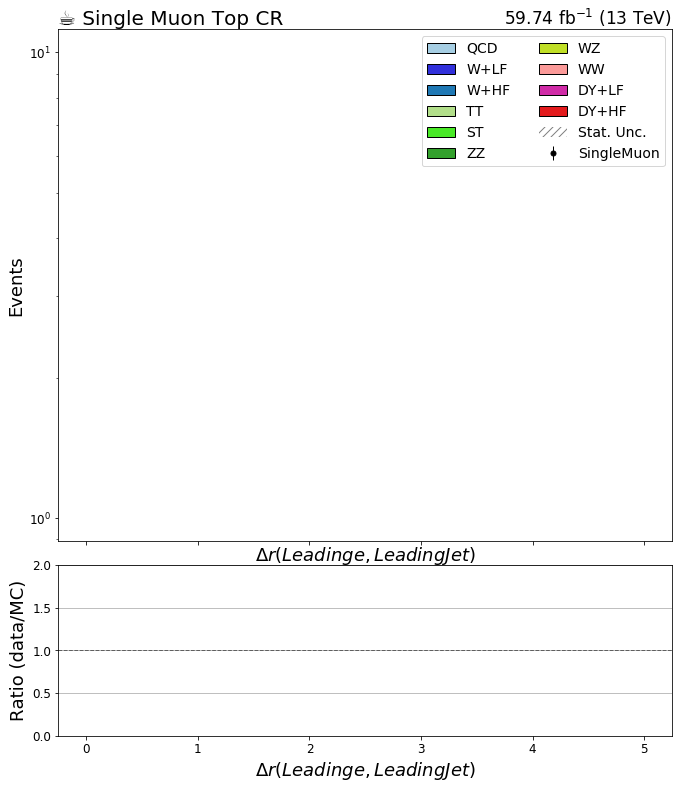

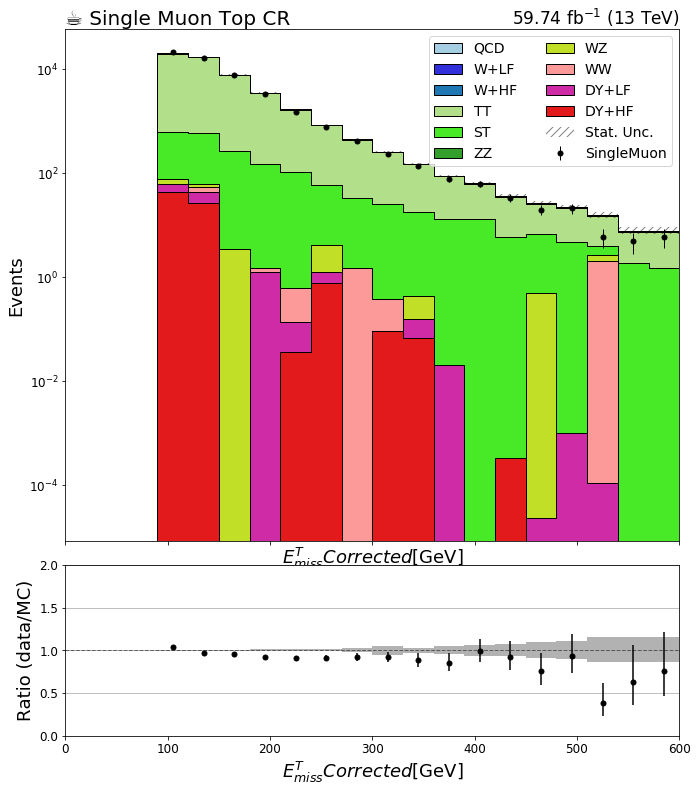

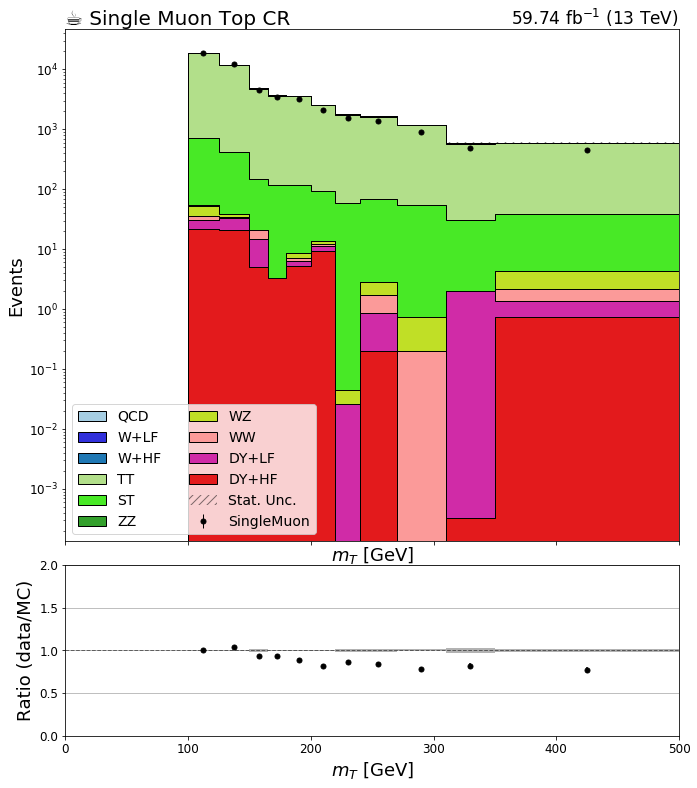

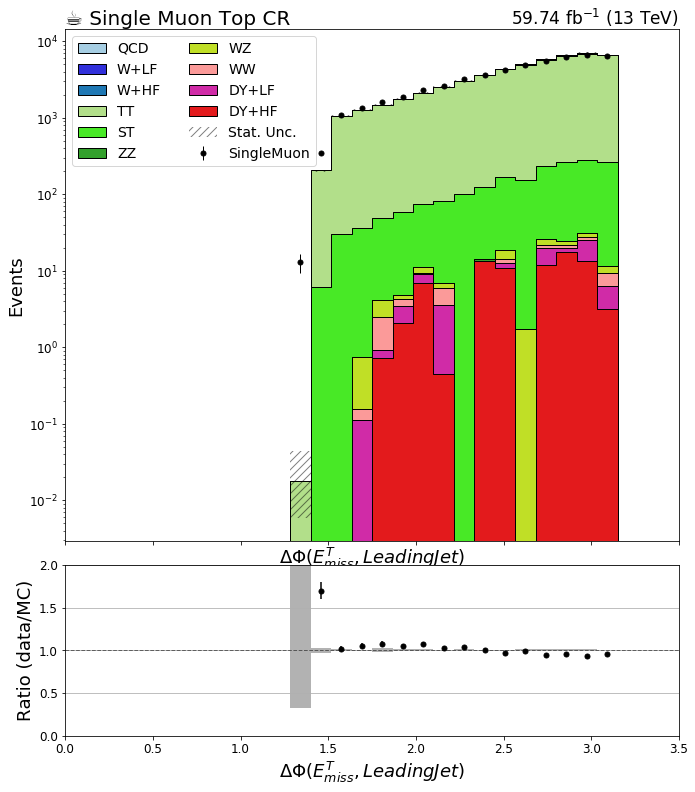

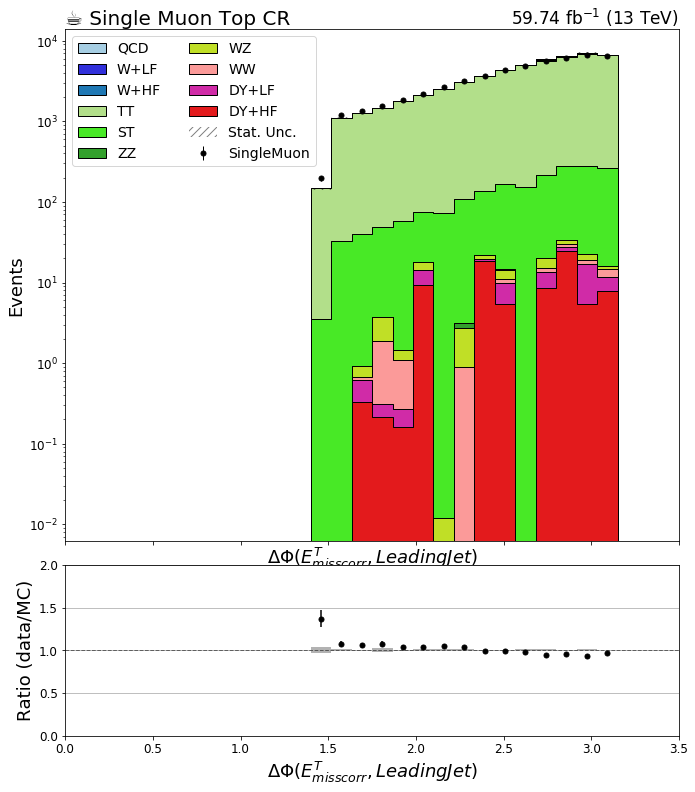

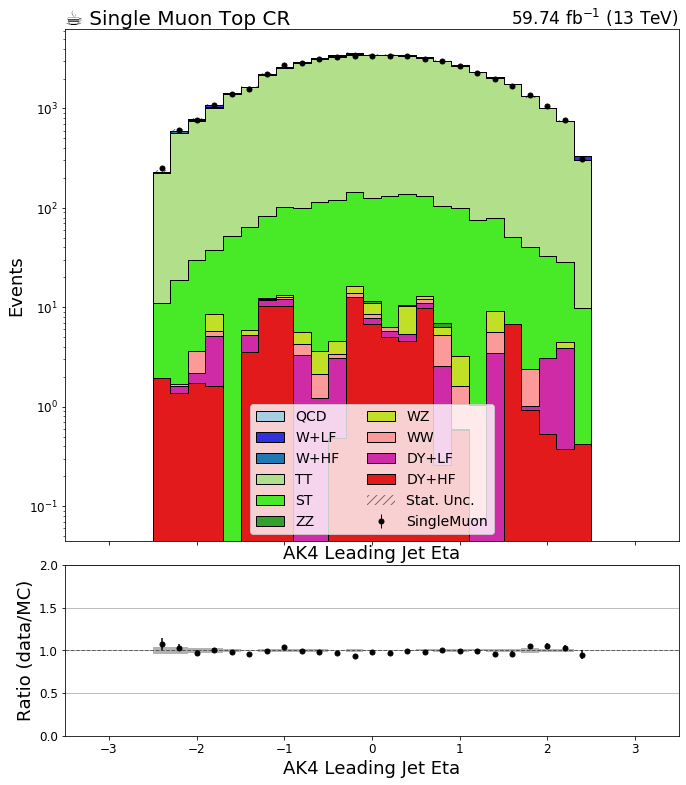

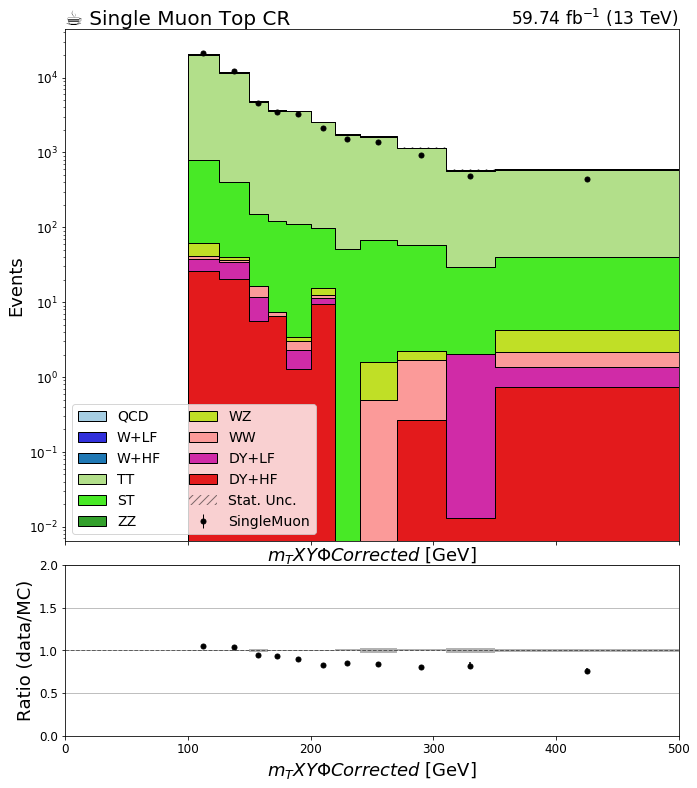

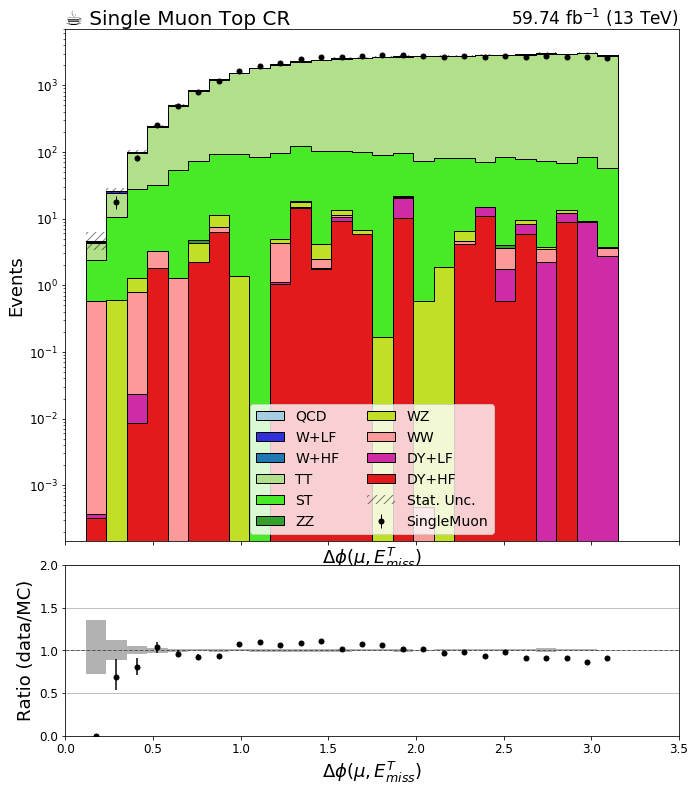

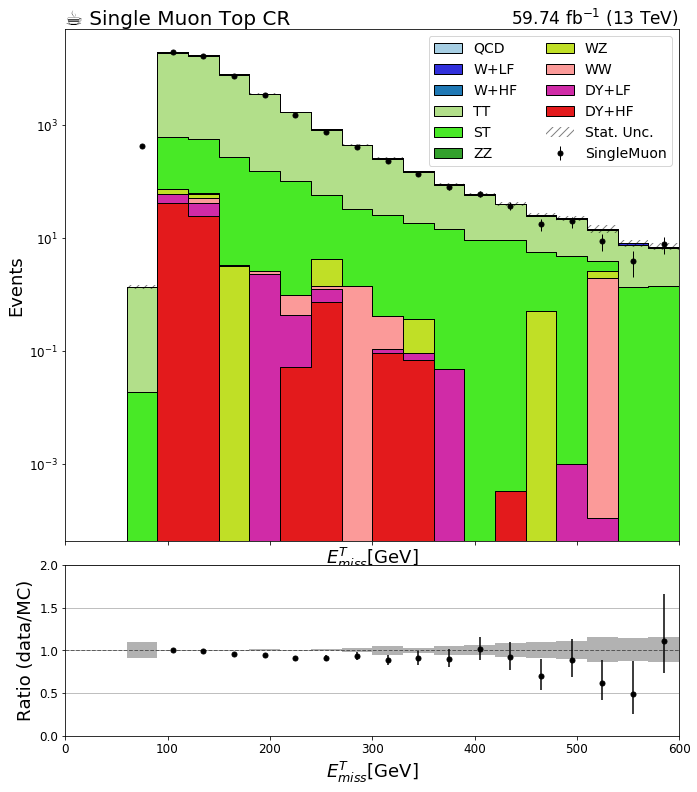

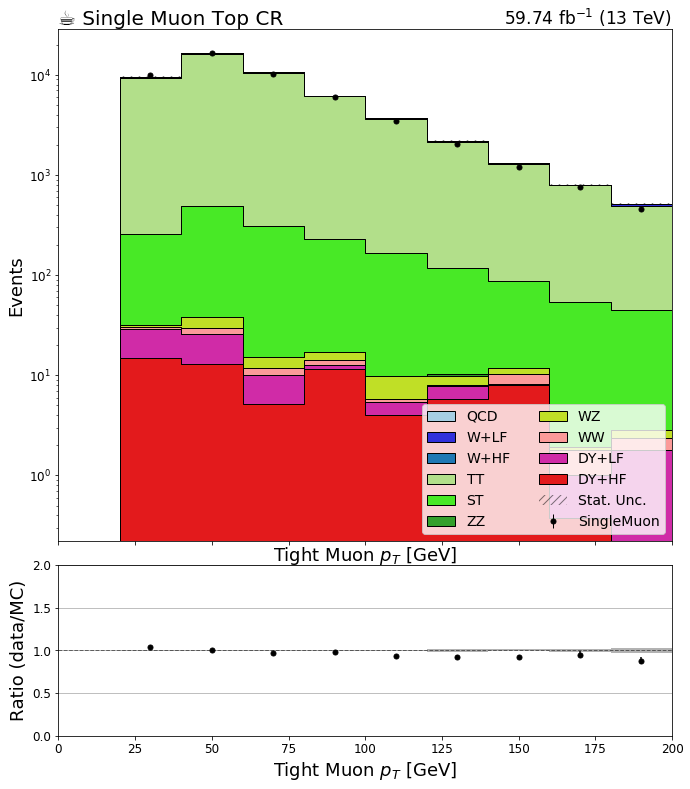

In [5]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2018'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('region',j).integrate('systematic', 'nominal')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('region',j).integrate('systematic', 'nominal').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"59.74 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

In [5]:
bkg_hists['mT_corrected'].integrate('region', 'ttbare').integrate('systematic', 'nominal').values()

{('DY+HF',): array([ 0.00000000e+00,  2.23485260e+01,  3.85191002e+01,  4.65712782e+01,
         1.77486632e+01, -3.80175158e+00,  9.72950151e+00,  2.15841095e+01,
         1.29833578e+01,  4.56635402e+00,  5.14767147e-01, -2.35719384e+00,
        -1.98148279e-02,  1.34123924e-03,  1.80871712e-02,  8.53518465e-02,
        -4.42332400e-02, -2.48405250e-02,  4.40139974e-02,  2.20553317e-03]),
 ('DY+LF',): array([ 0.00000000e+00, -5.17763437e+00,  1.57095265e+01,  2.28485086e+00,
         1.98864417e+01,  7.23365718e+00,  1.50816422e-01, -7.25246602e+00,
         4.12925963e-01,  3.02545483e+00,  8.65257177e-02, -1.17513816e-01,
         8.52496200e-02, -3.34645839e-02,  1.29007959e-02,  1.62569979e-02,
         6.82502873e-02,  9.54260336e-03,  2.53069400e-03,  6.23816282e-03]),
 ('WW',): array([0.        , 1.58271463, 6.07009041, 7.95589856, 6.96528783,
        6.42283614, 1.37821997, 1.71358028, 2.66123447, 1.82270678,
        0.        , 0.4473097 , 0.36704137, 0.        , 0.        ,

In [14]:
data_hists['template'].integrate('region', 'wjete').integrate('systematic', 'nominal').values()

{('EGamma',): array([    0., 19658., 58062., 46942., 48073., 50924., 28888., 14121.,
         7153.,  3879.,  2214.,  1301.,   839.,   504.,   378.,   241.,
          165.,   122.,    96.,    72.])}

In [8]:
bkg_hists['template'].integrate('region', 'ttbarm').integrate('systematic', 'nominal').values()

{('DY+HF',): array([ 8.74224081e+00,  1.59011987e+01,  6.57934468e+00,  1.07532802e+00,
        -9.34190447e-01,  2.56983052e+01,  1.07996229e+01,  2.06550578e-02,
         5.93240606e+00,  7.36563855e-05,  0.00000000e+00,  1.81309214e+00,
         1.72800935e-02,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00]),
 ('DY+LF',): array([-7.27773743e-01,  2.87229768e-02,  2.17133321e+00,  4.44464282e+00,
         1.85930739e+00,  7.41034910e+00, -2.92884325e-01,  4.29287864e+00,
         3.91056175e-03,  9.48582605e-05,  4.27958728e-03,  0.00000000e+00,
         1.82624134e-02,  0.00000000e+00,  1.96718517e-03,  0.00000000e+00,
         1.51166352e-03,  7.94373987e-04,  0.00000000e+00,  0.00000000e+00]),
 ('WW',): array([0.        , 0.        , 0.5880711 , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.46481188,
        0.        , 0.        , 0.        , 0.        , 0.        ,

In [18]:
bkg_hists

{'template': <Hist (process,region,systematic,mT_corrected) instance at 0x7f4caac80710>,
 'ele_phi': <Hist (process,region,systematic,ele_phi) instance at 0x7f4caaae39e8>,
 'sumw': <Hist (process,sumw) instance at 0x7f4caaa8ab00>,
 'j1pt': <Hist (process,region,systematic,j1pt) instance at 0x7f4caaa8bc88>,
 'eT_miss_corrected_phi': <Hist (process,region,systematic,eT_miss_corrected_phi) instance at 0x7f4caa180dd8>,
 'metphi': <Hist (process,region,systematic,metphi) instance at 0x7f4caa210eb8>,
 'ndflvM': <Hist (process,region,systematic,ndflvM) instance at 0x7f4ca9c66048>,
 'dr_mu_lj': <Hist (process,region,systematic,dr_mu_lj) instance at 0x7f4ca9c1b128>,
 'ele_pT': <Hist (process,region,systematic,ele_pT) instance at 0x7f4caa090208>,
 'mu_eta': <Hist (process,region,systematic,mu_eta) instance at 0x7f4caa94f320>,
 'j1phi': <Hist (process,region,systematic,j1phi) instance at 0x7f4caa26b438>,
 'leading_mu_pT': <Hist (process,region,systematic,leading_mu_pT) instance at 0x7f4caa9ea518>

In [20]:
bkg_hists['W_gen_pT'].integrate('region', 'wjete').integrate('systematic', 'nominal').values()

{('DY+HF',): array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 ('DY+LF',): array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 ('WW',): array([298.8403021 , 630.32649574, 633.797292  , 542.68770452,
        617.33335179, 566.49050792, 628.73492757, 589.08699921,
        520.73002751, 384.49564646, 343.42019192, 250.53923145,
        209.81101556, 169.8301269 , 166.72745633, 102.53110417,
         82.20668645,  89.55795307,  94.14886255,  42.80952221,
         30.55115907,  30.46063219,  23.05463427,  19.09733836,
         12.14926435,  22.17518863,  12.61485791,  11.76032449,
         12.91453343,  10.30303003,   9.19454347,   9.03152955,
   

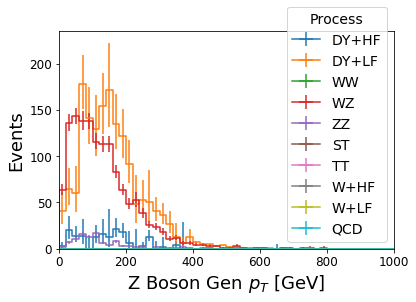

In [23]:
plot.plot1d(bkg_hists['Z_gen_pT'].integrate('region', 'wjete').integrate('systematic', 'nominal'),
           overlay='process')